In [ ]:

# ============================================================
# CELL 0: ENVIRONMENT & CONFIGURATION
# ============================================================

from google.colab import drive
from pathlib import Path
import numpy as np
import torch
import random
import json
import pickle

# Mount Google Drive
drive.mount("/content/drive", force_remount=False)

# -------------------- PATHS --------------------

BASE_DIR = Path("/content/drive/MyDrive/LoRe")

PERSONAL_DIR = BASE_DIR / "PersonalLLM_embeddings"
PERSONAL_RUNS_DIR = BASE_DIR / "PersonalLLM_runs"

REDDIT_DIR = BASE_DIR / "RedditTLDR_embeddings"

OUTPUT_DIR = BASE_DIR / "Architecture_Ablations" / "final_v1"
PROJECTION_DIR = OUTPUT_DIR / "projections"
SPLIT_DIR = OUTPUT_DIR / "data_splits"

# Create experiment directories
for directory in [
    OUTPUT_DIR,
    PROJECTION_DIR,
    SPLIT_DIR,
    OUTPUT_DIR / "PersonalLLM",
    OUTPUT_DIR / "RedditTLDR",
    OUTPUT_DIR / "summaries",
    OUTPUT_DIR / "final_comparison",
]:
    directory.mkdir(parents=True, exist_ok=True)

# -------------------- DEVICE & RANDOM SEEDS --------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEEDS = [42, 43, 44, 45, 46]

# -------------------- MODEL CONFIGURATION --------------------

K = 5
EMBEDDING_DIM = 4096
PROJECTION_DIM = 512

SEEN_STEPS = 2000
UNSEEN_STEPS = 1000

BASIS_LR = 0.01
USER_LR = 0.5
UNSEEN_LR = 0.1

# -------------------- EXPECTED SOURCE FILES --------------------

SOURCE_FILES = {
    "PersonalLLM train embeddings":
        PERSONAL_DIR / "train.safetensors",

    "PersonalLLM test embeddings":
        PERSONAL_DIR / "test.safetensors",

    "PersonalLLM synthetic setup":
        PERSONAL_RUNS_DIR / "personal_llm_synthetic_setup.npz",

    "Reddit train comparisons":
        REDDIT_DIR / "tldr_embeddings_train.pkl",

    "Reddit validation comparisons":
        REDDIT_DIR / "tldr_embeddings_val.pkl",

    "Reddit user split":
        REDDIT_DIR / "user_split.json",
}

print("=" * 55)
print("LoRe Architecture Ablations — Final Experiment")
print("=" * 55)

print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

print(f"Seeds: {SEEDS}")
print(f"Embedding dimension: {EMBEDDING_DIM}")
print(f"Shared basis dimension: {K}")
print(f"Output directory: {OUTPUT_DIR}")

print("\nSource file verification:")
missing_files = []

for name, path in SOURCE_FILES.items():
    exists = path.exists()
    print(f"{'✓' if exists else '✗'} {name}: {path}")
    if not exists:
        missing_files.append(path)

if missing_files:
    raise FileNotFoundError(
        "Missing source files:\n" +
        "\n".join(str(path) for path in missing_files)
    )

print("\nAll source files found. Configuration ready.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
LoRe Architecture Ablations — Final Experiment
Device: cuda
GPU: NVIDIA A100-SXM4-40GB
Seeds: [42, 43, 44, 45, 46]
Embedding dimension: 4096
Shared basis dimension: 5
Output directory: /content/drive/MyDrive/LoRe/Architecture_Ablations/final_v1

Source file verification:
✓ PersonalLLM train embeddings: /content/drive/MyDrive/LoRe/PersonalLLM_embeddings/train.safetensors
✓ PersonalLLM test embeddings: /content/drive/MyDrive/LoRe/PersonalLLM_embeddings/test.safetensors
✓ PersonalLLM synthetic setup: /content/drive/MyDrive/LoRe/PersonalLLM_runs/personal_llm_synthetic_setup.npz
✓ Reddit train comparisons: /content/drive/MyDrive/LoRe/RedditTLDR_embeddings/tldr_embeddings_train.pkl
✓ Reddit validation comparisons: /content/drive/MyDrive/LoRe/RedditTLDR_embeddings/tldr_embeddings_val.pkl
✓ Reddit user split: /content/drive/MyDrive/LoRe/RedditTLDR_embeddings/user_spl

In [ ]:

# ============================================================
# CELL 1: LOAD PERSONALLLM DATA
# ============================================================

from safetensors.torch import load_file

NUM_RESPONSES = 8

# -------------------- LOAD EMBEDDINGS --------------------

personal_train_tensors = load_file(
    str(PERSONAL_DIR / "train.safetensors")
)

personal_test_tensors = load_file(
    str(PERSONAL_DIR / "test.safetensors")
)

def get_embedding_tensor(tensor_dict, name):
    print(f"\n{name} tensor contents:")

    for key, value in tensor_dict.items():
        print(f"  {key}: {tuple(value.shape)} | {value.dtype}")

    # Prefer a recognizable embedding key.
    candidates = [
        "embeddings",
        "embedding",
        "last_hidden_state",
    ]

    for key in candidates:
        if key in tensor_dict:
            return tensor_dict[key]

    # If there is only one tensor, use it.
    if len(tensor_dict) == 1:
        return next(iter(tensor_dict.values()))

    raise ValueError(
        f"Could not identify the embedding tensor in {name}. "
        "Please inspect the printed keys."
    )


personal_train_flat = get_embedding_tensor(
    personal_train_tensors, "PersonalLLM train"
)

personal_test_flat = get_embedding_tensor(
    personal_test_tensors, "PersonalLLM test"
)

# Reshape: flattened responses -> prompts x responses x dimensions
personal_train_emb = personal_train_flat.reshape(
    -1, NUM_RESPONSES, EMBEDDING_DIM
).float()

personal_test_emb = personal_test_flat.reshape(
    -1, NUM_RESPONSES, EMBEDDING_DIM
).float()

# -------------------- LOAD SYNTHETIC SETUP --------------------

personal_setup = np.load(
    PERSONAL_RUNS_DIR / "personal_llm_synthetic_setup.npz"
)

print("\nSynthetic setup contents:")

for key in personal_setup.files:
    print(f"  {key}: {personal_setup[key].shape if personal_setup[key].ndim else personal_setup[key]}")

W_seen_true = personal_setup["W_seen_true"]
W_unseen_true = personal_setup["W_unseen_true"]

seen_prompt_indices = personal_setup["seen_prompt_indices"]
unseen_prompt_indices = personal_setup["unseen_prompt_indices"]

personal_seed = (
    personal_setup["seed"].item()
    if "seed" in personal_setup.files else None
)

personal_alpha = (
    personal_setup["alpha"].item()
    if "alpha" in personal_setup.files else None
)

# -------------------- INSPECT OTHER PERSONALLLM FILES --------------------

print("\nOther files available:")

for folder in [PERSONAL_DIR, PERSONAL_RUNS_DIR]:
    print(f"\n{folder.name}/")
    for path in sorted(folder.iterdir()):
        if path.is_file():
            print(f"  {path.name} ({path.stat().st_size / (1024**2):.2f} MB)")

# -------------------- BASIC VALIDATION --------------------

assert personal_train_emb.ndim == 3
assert personal_test_emb.ndim == 3

assert personal_train_emb.shape[1:] == (
    NUM_RESPONSES, EMBEDDING_DIM
)

assert personal_test_emb.shape[1:] == (
    NUM_RESPONSES, EMBEDDING_DIM
)

assert W_seen_true.shape == (1000, 10)
assert W_unseen_true.shape == (500, 10)

assert seen_prompt_indices.shape == (1000, 47)
assert unseen_prompt_indices.shape == (500, 9)

print("\n" + "=" * 50)
print("PERSONALLLM LOADING COMPLETE")
print("=" * 50)

print("Train embeddings:", tuple(personal_train_emb.shape))
print("Test embeddings:", tuple(personal_test_emb.shape))
print("Seen user weights:", W_seen_true.shape)
print("Unseen user weights:", W_unseen_true.shape)
print("Seen prompt indices:", seen_prompt_indices.shape)
print("Unseen prompt indices:", unseen_prompt_indices.shape)
print("Original seed:", personal_seed)
print("Alpha:", personal_alpha)



PersonalLLM train tensor contents:
  embeddings: (75216, 4096) | torch.bfloat16

PersonalLLM test tensor contents:
  embeddings: (8000, 4096) | torch.bfloat16

Synthetic setup contents:
  W_seen_true: (1000, 10)
  W_unseen_true: (500, 10)
  seen_prompt_indices: (1000, 47)
  unseen_prompt_indices: (500, 9)
  seed: 42
  alpha: 0.1

Other files available:

PersonalLLM_embeddings/
  smoke_test.pt (0.02 MB)
  test.safetensors (62.50 MB)
  train.safetensors (587.63 MB)

PersonalLLM_runs/
  personal_llm_synthetic_setup.npz (0.22 MB)
  personalllm_lore_K5_fewshot.pt (0.09 MB)
  personalllm_lore_K5_final.pt (0.52 MB)
  personalllm_lore_K5_joint.pt (0.25 MB)
  personalllm_lore_K5_results.json (0.00 MB)
  personalllm_lore_K5_results.png (0.04 MB)

PERSONALLLM LOADING COMPLETE
Train embeddings: (9402, 8, 4096)
Test embeddings: (1000, 8, 4096)
Seen user weights: (1000, 10)
Unseen user weights: (500, 10)
Seen prompt indices: (1000, 47)
Unseen prompt indices: (500, 9)
Original seed: 42
Alpha: 0.1


In [ ]:

# ============================================================
# CELL 2: FIND PERSONALLLM REWARD SCORES
# ============================================================

# Search filenames throughout the LoRe directory
keywords = ["score", "reward", "preference", "response"]

print("Potential reward/preference data files:\n")

matches = []

for path in BASE_DIR.rglob("*"):
    if not path.is_file():
        continue

    # Ignore the new experiment output directory
    if OUTPUT_DIR in path.parents:
        continue

    if any(word in path.name.lower() for word in keywords):
        matches.append(path)

if matches:
    for path in matches:
        print(f"{path} ({path.stat().st_size / (1024**2):.2f} MB)")
else:
    print("No files found with matching names.")

# Inspect existing PersonalLLM LoRe checkpoints
print("\nExisting PersonalLLM checkpoint contents:\n")

checkpoint_names = [
    "personalllm_lore_K5_final.pt",
    "personalllm_lore_K5_joint.pt",
    "personalllm_lore_K5_fewshot.pt",
]

for filename in checkpoint_names:
    path = PERSONAL_RUNS_DIR / filename

    if not path.exists():
        continue

    print(f"\n{filename}:")

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        if isinstance(checkpoint, dict):
            for key, value in checkpoint.items():
                if torch.is_tensor(value):
                    print(f"  {key}: Tensor {tuple(value.shape)}")
                elif isinstance(value, np.ndarray):
                    print(f"  {key}: Array {value.shape}")
                else:
                    print(f"  {key}: {type(value).__name__}")
        else:
            print("  Object type:", type(checkpoint).__name__)

    except Exception as error:
        print("  Could not inspect:", error)

print("\nReward-score search complete.")


Potential reward/preference data files:

No files found with matching names.

Existing PersonalLLM checkpoint contents:


personalllm_lore_K5_final.pt:
  V: Tensor (4096, 5)
  W_seen: Tensor (1000, 5)
  W_unseen: Tensor (500, 5)
  W_seen_true: Array (1000, 10)
  W_unseen_true: Array (500, 10)
  seen_prompt_indices: Array (1000, 47)
  unseen_prompt_indices: Array (500, 9)
  config: dict
  results: dict
  joint_loss_history: list
  fewshot_loss_history: list

personalllm_lore_K5_joint.pt:
  V: Tensor (4096, 5)
  W_seen: Tensor (1000, 5)
  W_seen_logits: Tensor (1000, 5)
  W_seen_true: Array (1000, 10)
  seed: int
  K: int
  alpha_user: float
  regularization_alpha: float
  learning_rate: float
  num_steps: int
  loss_history: list

personalllm_lore_K5_fewshot.pt:
  W_unseen: Tensor (500, 5)
  W_unseen_true: Array (500, 10)
  fewshot_prompt_indices: Array (500, 9)
  fewshot_loss_history: list

Reward-score search complete.


In [ ]:

# ============================================================
# CELL 3: LOAD REDDIT TL;DR
# ============================================================

# -------------------- LOAD FILES --------------------

with open(REDDIT_DIR / "tldr_embeddings_train.pkl", "rb") as f:
    reddit_train_raw = pickle.load(f)

with open(REDDIT_DIR / "tldr_embeddings_val.pkl", "rb") as f:
    reddit_val_raw = pickle.load(f)

with open(REDDIT_DIR / "user_split.json", "r") as f:
    reddit_split = json.load(f)


# -------------------- INSPECT DATA STRUCTURE --------------------

def inspect_reddit_data(data, name):
    print(f"\n{name}")
    print("-" * 45)
    print("Container type:", type(data).__name__)
    print("Number of entries:", len(data))

    if isinstance(data, dict):
        print("Top-level keys:", list(data.keys())[:10])

        # Inspect the first value
        first_key = next(iter(data))
        first = data[first_key]

    elif isinstance(data, (list, tuple)):
        first = data[0] if len(data) else None

    else:
        print("Unexpected container structure.")
        return

    if first is None:
        print("Empty data.")
        return

    print("First entry type:", type(first).__name__)

    if isinstance(first, dict):
        print("First entry keys:", list(first.keys()))

        for key, value in first.items():
            if torch.is_tensor(value):
                print(f"  {key}: Tensor {tuple(value.shape)}")

            elif isinstance(value, np.ndarray):
                print(f"  {key}: Array {value.shape}")

            elif isinstance(value, dict):
                print(f"  {key}: dictionary")
                for subkey, subvalue in value.items():
                    if torch.is_tensor(subvalue):
                        print(f"      {subkey}: Tensor {tuple(subvalue.shape)}")
                    elif isinstance(subvalue, (list, tuple)):
                        print(f"      {subkey}: {type(subvalue).__name__}, length {len(subvalue)}")
                    else:
                        print(f"      {subkey}: {type(subvalue).__name__}")

            elif isinstance(value, (list, tuple)):
                print(f"  {key}: {type(value).__name__}, length {len(value)}")

            else:
                print(f"  {key}: {type(value).__name__}")


inspect_reddit_data(reddit_train_raw, "REDDIT TRAIN")
inspect_reddit_data(reddit_val_raw, "REDDIT VALIDATION")


# -------------------- INSPECT WORKER SPLIT --------------------

print("\nWORKER SPLIT")
print("-" * 45)

print("Available keys:", list(reddit_split.keys()))

for key, value in reddit_split.items():
    if isinstance(value, (list, tuple, set)):
        print(f"{key}: {len(value)} workers")
        print("  Sample:", list(value)[:5])
    else:
        print(f"{key}: {value}")

print("\nReddit data loaded successfully.")



REDDIT TRAIN
---------------------------------------------
Container type: dict
Number of entries: 39
Top-level keys: ['qo6WIyEh27cwAjWpA3Q60J7NaDxzQJ', 'JwYQFRg76uas70g5HPUxA0jq6sEIo1', 'UhQipwcpQmiGJmScocXOGOKyCBaFUg', 'p4Oh7rUGyLe1EpilJFWr9sPDpkO016', 'i8YiBZlrYmlkkChr5b9BUKvDO6lR1d', 'mjwVX7RHTcfOfLTYGdBvms3vy8LTtP', 'eqG43fefProZXdcmCckXe2IgcAe2SL', 'I7j9xixai8hrT0M1vDWziiURvIsHUL', 'RMwrIV50cNusBthNvLs1wSNdqFpQAg', 'OKFDIsAZl6Qa0m9x26f5Ao4S0uc7Ca']
First entry type: list

REDDIT VALIDATION
---------------------------------------------
Container type: dict
Number of entries: 39
Top-level keys: ['7ohpEDc6oqdYm2So8i7IrCrArikSRy', 'chGNutbQlSMp2PN1z8pb8qXyNdIWyo', 'XxIBEfyZigAJyqYeRnjaZsq4ADwPmW', 'V4kZVolIcM13xFttt12rzhEn7krHK4', 'eqG43fefProZXdcmCckXe2IgcAe2SL', 'I7j9xixai8hrT0M1vDWziiURvIsHUL', 'sC4a4UNRMSYCGopXr3K8znnyna6TVh', 'p4Oh7rUGyLe1EpilJFWr9sPDpkO016', 'ZzGCcAhvqF0HnKxNsUjtJFadcZdyZj', 'p7cM83bE3XsWlS9lTIvYCNfCVgOeTK']
First entry type: list

WORKER SPLIT
---------------

In [ ]:

# ============================================================
# CELL 4: PREPARE REDDIT COMPARISONS
# ============================================================

def extract_worker_records(data):
    """Convert the loaded data into {worker_id: list_of_records}."""

    if isinstance(data, dict):
        # Expected format: worker_id -> list of comparison records
        if all(isinstance(v, (list, tuple)) for v in data.values()):
            return {str(k): v for k, v in data.items()}

        raise ValueError(
            "Unexpected Reddit dictionary structure. "
            "Inspect the output of Cell 3."
        )

    if isinstance(data, list):
        # Support a flat list of records containing worker identifiers.
        worker_fields = [
            "worker_id", "worker", "user_id", "annotator_id"
        ]

        if not data:
            return {}

        worker_field = next(
            (key for key in worker_fields if key in data[0]),
            None
        )

        if worker_field is None:
            raise ValueError("Could not identify the worker ID field.")

        grouped = {}

        for record in data:
            worker = str(record[worker_field])
            grouped.setdefault(worker, []).append(record)

        return grouped

    raise TypeError(f"Unsupported data type: {type(data)}")


def get_embedding_vector(value):
    """Extract one 4096-dimensional embedding from a stored value."""

    if isinstance(value, (list, tuple)):
        if len(value) == 1:
            value = value[0]

    vector = torch.as_tensor(value).float().reshape(-1)

    if vector.numel() != EMBEDDING_DIM:
        raise ValueError(
            f"Expected {EMBEDDING_DIM} dimensions, "
            f"found {vector.numel()}."
        )

    return vector


def prepare_reddit_pairs(data):
    """Create winning/losing embedding tensors for every worker."""

    data_by_worker = extract_worker_records(data)
    prepared = {}

    for worker, records in data_by_worker.items():
        winning = []
        losing = []

        for record in records:
            embeddings = record["embeddings"]

            winning.append(
                get_embedding_vector(embeddings["winning"])
            )

            losing.append(
                get_embedding_vector(embeddings["losing"])
            )

        if records:
            prepared[worker] = {
                "winning": torch.stack(winning),
                "losing": torch.stack(losing),
            }

    return prepared


# -------------------- PREPARE TRAIN / VALIDATION --------------------

reddit_train_pairs = prepare_reddit_pairs(reddit_train_raw)
reddit_val_pairs = prepare_reddit_pairs(reddit_val_raw)

# -------------------- WORKER SPLIT --------------------

reddit_seen_users = set(map(str, reddit_split["seen_workers"]))
reddit_unseen_users = set(map(str, reddit_split["unseen_workers"]))

assert reddit_seen_users.isdisjoint(reddit_unseen_users)

reddit_all_users = reddit_seen_users | reddit_unseen_users

# -------------------- VERIFY --------------------

def count_comparisons(data, workers):
    return sum(
        data[user]["winning"].shape[0]
        for user in workers
        if user in data
    )


train_workers = set(reddit_train_pairs)
val_workers = set(reddit_val_pairs)

print("=" * 55)
print("REDDIT TL;DR PREPARATION")
print("=" * 55)

print(f"Seen workers: {len(reddit_seen_users)}")
print(f"Unseen workers: {len(reddit_unseen_users)}")
print(f"Total workers: {len(reddit_all_users)}")

print("\nTraining comparisons:")
print("  Seen:", count_comparisons(reddit_train_pairs, reddit_seen_users))
print("  Unseen:", count_comparisons(reddit_train_pairs, reddit_unseen_users))
print("  Total:", count_comparisons(reddit_train_pairs, reddit_all_users))

print("\nValidation comparisons:")
print("  Seen:", count_comparisons(reddit_val_pairs, reddit_seen_users))
print("  Unseen:", count_comparisons(reddit_val_pairs, reddit_unseen_users))
print("  Total:", count_comparisons(reddit_val_pairs, reddit_all_users))

print("\nWorker coverage:")
print("  Missing from training:", sorted(reddit_all_users - train_workers))
print("  Missing from validation:", sorted(reddit_all_users - val_workers))
print("  Unexpected training workers:", sorted(train_workers - reddit_all_users))
print("  Unexpected validation workers:", sorted(val_workers - reddit_all_users))

# Check every worker's tensor dimensions
for dataset in [reddit_train_pairs, reddit_val_pairs]:
    for worker, pairs in dataset.items():
        assert pairs["winning"].shape == pairs["losing"].shape
        assert pairs["winning"].shape[1] == EMBEDDING_DIM

assert train_workers == reddit_all_users
assert val_workers == reddit_all_users

print("\nSample worker tensor shapes:")
sample_worker = sorted(reddit_train_pairs)[0]
print("  Worker:", sample_worker)
print("  Winning:", tuple(reddit_train_pairs[sample_worker]["winning"].shape))
print("  Losing:", tuple(reddit_train_pairs[sample_worker]["losing"].shape))

print("\nReddit comparisons prepared successfully.")


REDDIT TL;DR PREPARATION
Seen workers: 20
Unseen workers: 19
Total workers: 39

Training comparisons:
  Seen: 2915
  Unseen: 950
  Total: 3865

Validation comparisons:
  Seen: 5566
  Unseen: 4709
  Total: 10275

Worker coverage:
  Missing from training: []
  Missing from validation: []
  Unexpected training workers: []
  Unexpected validation workers: []

Sample worker tensor shapes:
  Worker: 3AFaFd3w9NjDGnO51kupLyK1N44DQ2
  Winning: (150, 4096)
  Losing: (150, 4096)

Reddit comparisons prepared successfully.


In [ ]:

# ============================================================
# CELL 5: UNIFIED BENCHMARK REPRESENTATION
# ============================================================

def make_delta_data(pair_data, workers):
    """Convert worker comparisons into winner-minus-loser features."""

    result = {}

    for worker in sorted(workers):
        if worker not in pair_data:
            continue

        winning = pair_data[worker]["winning"]
        losing = pair_data[worker]["losing"]

        result[worker] = (winning - losing).contiguous()

    return result


# -------------------- REDDIT UNIFIED DATA --------------------

reddit_data = {
    "name": "RedditTLDR",

    "seen_users": sorted(reddit_seen_users),
    "unseen_users": sorted(reddit_unseen_users),

    # Seen users: used to train the shared basis and user weights
    "seen_train": make_delta_data(
        reddit_train_pairs, reddit_seen_users
    ),

    # Unseen users: used only for few-shot adaptation
    "unseen_fewshot": make_delta_data(
        reddit_train_pairs, reddit_unseen_users
    ),

    # Held-out validation comparisons
    "seen_eval": make_delta_data(
        reddit_val_pairs, reddit_seen_users
    ),

    "unseen_eval": make_delta_data(
        reddit_val_pairs, reddit_unseen_users
    ),
}


# -------------------- VERIFY UNIFIED DATA --------------------

def validate_benchmark(data):
    assert set(data["seen_users"]).isdisjoint(
        data["unseen_users"]
    )

    expected_splits = [
        "seen_train",
        "unseen_fewshot",
        "seen_eval",
        "unseen_eval",
    ]

    for split in expected_splits:
        assert data[split], f"{split} is empty."

        for worker, delta in data[split].items():
            assert delta.ndim == 2
            assert delta.shape[1] == EMBEDDING_DIM
            assert torch.isfinite(delta).all()

    assert set(data["seen_train"]) == set(data["seen_users"])
    assert set(data["unseen_fewshot"]) == set(data["unseen_users"])

    assert set(data["seen_eval"]) == set(data["seen_users"])
    assert set(data["unseen_eval"]) == set(data["unseen_users"])


validate_benchmark(reddit_data)


# -------------------- SUMMARY --------------------

print("=" * 55)
print("UNIFIED REDDIT BENCHMARK")
print("=" * 55)

for split in [
    "seen_train",
    "unseen_fewshot",
    "seen_eval",
    "unseen_eval",
]:
    comparisons = sum(
        tensor.shape[0]
        for tensor in reddit_data[split].values()
    )

    users = len(reddit_data[split])

    print(
        f"{split:18s} | "
        f"Users: {users:2d} | "
        f"Comparisons: {comparisons:5d}"
    )

print("\nFeature dimension:", EMBEDDING_DIM)
print("Seen users:", len(reddit_data["seen_users"]))
print("Unseen users:", len(reddit_data["unseen_users"]))

# -------------------- PERSONALLLM STATUS --------------------

personal_data = None

print("\nPersonalLLM: PENDING")
print("Reason: Original 10-dimensional reward scores are not")
print("available in the currently identified source files.")

print("\nReddit unified representation ready.")


UNIFIED REDDIT BENCHMARK
seen_train         | Users: 20 | Comparisons:  2915
unseen_fewshot     | Users: 19 | Comparisons:   950
seen_eval          | Users: 20 | Comparisons:  5566
unseen_eval        | Users: 19 | Comparisons:  4709

Feature dimension: 4096
Seen users: 20
Unseen users: 19

PersonalLLM: PENDING
Reason: Original 10-dimensional reward scores are not
available in the currently identified source files.

Reddit unified representation ready.


In [ ]:

# ============================================================
# CELL 6: RECOVER PERSONALLLM SCORES & PREFERENCE PAIRS
# ============================================================

# Load the original benchmark dataset
try:
    from datasets import load_dataset
except ImportError:
    import subprocess, sys
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "datasets"
    ])
    from datasets import load_dataset

hf_dataset = load_dataset("namkoong-lab/PersonalLLM")

# Exact reward-model ordering used by the official LoRe implementation
PERSONAL_MODEL_NAMES = [
    "gemma_2b",
    "gemma_7b",
    "mistral_raft",
    "llama3_sfairx",
    "oasst_deberta_v3",
    "beaver_7b",
    "oasst_pythia_7b",
    "oasst_pythia_1b",
    "mistral_ray",
    "mistral_weqweasdas",
]

# -------------------- EXTRACT REWARD SCORES --------------------

def extract_reward_scores(split):
    data = hf_dataset[split]
    scores = np.empty(
        (len(data), NUM_RESPONSES, len(PERSONAL_MODEL_NAMES)),
        dtype=np.float32
    )

    for response_idx in range(NUM_RESPONSES):
        for model_idx, model_name in enumerate(PERSONAL_MODEL_NAMES):
            column = f"response_{response_idx + 1}_{model_name}"
            scores[:, response_idx, model_idx] = np.asarray(
                data[column], dtype=np.float32
            )

    return scores


personal_train_scores = extract_reward_scores("train")
personal_test_scores = extract_reward_scores("test")

assert personal_train_scores.shape == (9402, 8, 10)
assert personal_test_scores.shape == (1000, 8, 10)
assert np.isfinite(personal_train_scores).all()
assert np.isfinite(personal_test_scores).all()

# Save recovered scores so we never need to download them again
np.savez_compressed(
    PERSONAL_DIR / "reward_scores.npz",
    train_scores=personal_train_scores,
    test_scores=personal_test_scores,
    model_names=np.asarray(PERSONAL_MODEL_NAMES),
)

# -------------------- RECONSTRUCT PREFERENCE PAIRS --------------------

def build_personal_pairs(scores, user_weights, prompt_indices):
    """
    For each user and selected prompt:
      1. Compute the weighted reward of all 8 responses.
      2. Select the highest-reward response as winner.
      3. Select the lowest-reward response as loser.
    """

    all_pairs = []

    for user_idx, weights in enumerate(user_weights):
        indices = np.asarray(
            prompt_indices[user_idx], dtype=np.int64
        )

        utilities = np.einsum(
            "nrm,m->nr",
            scores[indices],
            weights,
            optimize=True
        )

        all_pairs.append({
            "prompt_idx": indices,
            "winner_idx": utilities.argmax(axis=1),
            "loser_idx": utilities.argmin(axis=1),
        })

    return all_pairs


# Seen-user training pairs: 47 prompts per user
personal_seen_train = build_personal_pairs(
    personal_train_scores,
    W_seen_true,
    seen_prompt_indices
)

# Unseen-user adaptation pairs: 9 prompts per user
personal_unseen_fewshot = build_personal_pairs(
    personal_train_scores,
    W_unseen_true,
    unseen_prompt_indices
)

# Test: all 1,000 held-out prompts per user
all_test_indices = np.broadcast_to(
    np.arange(len(personal_test_scores)),
    (len(W_seen_true), len(personal_test_scores))
)

personal_seen_test = build_personal_pairs(
    personal_test_scores,
    W_seen_true,
    all_test_indices
)

all_test_indices_unseen = np.broadcast_to(
    np.arange(len(personal_test_scores)),
    (len(W_unseen_true), len(personal_test_scores))
)

personal_unseen_test = build_personal_pairs(
    personal_test_scores,
    W_unseen_true,
    all_test_indices_unseen
)

# -------------------- REPORT --------------------

print("=" * 55)
print("PERSONALLLM PREFERENCE RECONSTRUCTION")
print("=" * 55)

print("Training reward scores:", personal_train_scores.shape)
print("Test reward scores:", personal_test_scores.shape)

print("\nPreference comparisons:")
print("Seen training:", sum(len(p["prompt_idx"]) for p in personal_seen_train))
print("Unseen few-shot:", sum(len(p["prompt_idx"]) for p in personal_unseen_fewshot))
print("Seen test:", sum(len(p["prompt_idx"]) for p in personal_seen_test))
print("Unseen test:", sum(len(p["prompt_idx"]) for p in personal_unseen_test))

print("\nUsers:")
print("Seen:", len(personal_seen_train))
print("Unseen:", len(personal_unseen_fewshot))

print("\nSample comparison:")
print("Prompt:", personal_seen_train[0]["prompt_idx"][0])
print("Winner response:", personal_seen_train[0]["winner_idx"][0])
print("Loser response:", personal_seen_train[0]["loser_idx"][0])

print("\nReward scores saved to:", PERSONAL_DIR / "reward_scores.npz")
print("PersonalLLM preference reconstruction complete.")


PERSONALLLM PREFERENCE RECONSTRUCTION
Training reward scores: (9402, 8, 10)
Test reward scores: (1000, 8, 10)

Preference comparisons:
Seen training: 47000
Unseen few-shot: 4500
Seen test: 1000000
Unseen test: 500000

Users:
Seen: 1000
Unseen: 500

Sample comparison:
Prompt: 1172
Winner response: 1
Loser response: 0

Reward scores saved to: /content/drive/MyDrive/LoRe/PersonalLLM_embeddings/reward_scores.npz
PersonalLLM preference reconstruction complete.


In [ ]:

# ============================================================
# CELL 7: UNIFIED PERSONALLLM + REDDIT DATA
# ============================================================

# -------------------- PERSONALLLM DATA --------------------

personal_data = {
    "name": "PersonalLLM",
    "representation": "indexed",

    "seen_users": list(range(len(personal_seen_train))),
    "unseen_users": list(range(len(personal_unseen_fewshot))),

    "seen_train": personal_seen_train,
    "unseen_fewshot": personal_unseen_fewshot,
    "seen_eval": personal_seen_test,
    "unseen_eval": personal_unseen_test,

    "train_embeddings": personal_train_emb,
    "eval_embeddings": personal_test_emb,
}


# -------------------- REDDIT DATA --------------------

reddit_data["representation"] = "deltas"


# -------------------- COMMON BENCHMARK REGISTRY --------------------

benchmarks = {
    "PersonalLLM": personal_data,
    "RedditTLDR": reddit_data,
}


# -------------------- COMMON DELTA RETRIEVAL FUNCTION --------------------

def get_pair_deltas(benchmark, split, user, start=0, end=None):
    """
    Returns winner-minus-loser embedding differences.

    PersonalLLM:
        Retrieves differences lazily from response embeddings
        and stored preference indices.

    Reddit:
        Retrieves precomputed differences from worker tensors.
    """

    if benchmark["representation"] == "indexed":

        pairs = benchmark[split][user]

        prompts = torch.as_tensor(
            pairs["prompt_idx"][start:end],
            dtype=torch.long
        )

        winners = torch.as_tensor(
            pairs["winner_idx"][start:end],
            dtype=torch.long
        )

        losers = torch.as_tensor(
            pairs["loser_idx"][start:end],
            dtype=torch.long
        )

        embedding_key = (
            "train_embeddings"
            if split in ["seen_train", "unseen_fewshot"]
            else "eval_embeddings"
        )

        embeddings = benchmark[embedding_key]

        return (
            embeddings[prompts, winners].float()
            - embeddings[prompts, losers].float()
        )

    else:
        return benchmark[split][user][start:end].float()


# -------------------- UNIFIED SUMMARY --------------------

print("=" * 60)
print("UNIFIED BENCHMARKS")
print("=" * 60)

for name, benchmark in benchmarks.items():

    print(f"\n{name}")
    print("-" * 45)
    print("Seen users:", len(benchmark["seen_users"]))
    print("Unseen users:", len(benchmark["unseen_users"]))

    for split in [
        "seen_train",
        "unseen_fewshot",
        "seen_eval",
        "unseen_eval",
    ]:
        users = benchmark[split]

        if benchmark["representation"] == "indexed":
            comparisons = sum(
                len(pairs["prompt_idx"])
                for pairs in users
            )
        else:
            comparisons = sum(
                delta.shape[0]
                for delta in users.values()
            )

        print(
            f"{split:18s}: "
            f"{len(users)} users, {comparisons:,} comparisons"
        )


# -------------------- TEST COMMON INTERFACE --------------------

personal_sample = get_pair_deltas(
    personal_data, "seen_train", user=0
)

reddit_sample = get_pair_deltas(
    reddit_data, "seen_train",
    user=reddit_data["seen_users"][0]
)

assert personal_sample.shape == (47, EMBEDDING_DIM)
assert reddit_sample.shape[1] == EMBEDDING_DIM

print("\nCommon interface works for both benchmarks.")
print("PersonalLLM sample:", tuple(personal_sample.shape))
print("Reddit sample:", tuple(reddit_sample.shape))


UNIFIED BENCHMARKS

PersonalLLM
---------------------------------------------
Seen users: 1000
Unseen users: 500
seen_train        : 1000 users, 47,000 comparisons
unseen_fewshot    : 500 users, 4,500 comparisons
seen_eval         : 1000 users, 1,000,000 comparisons
unseen_eval       : 500 users, 500,000 comparisons

RedditTLDR
---------------------------------------------
Seen users: 20
Unseen users: 19
seen_train        : 20 users, 2,915 comparisons
unseen_fewshot    : 19 users, 950 comparisons
seen_eval         : 20 users, 5,566 comparisons
unseen_eval       : 19 users, 4,709 comparisons

Common interface works for both benchmarks.
PersonalLLM sample: (47, 4096)
Reddit sample: (150, 4096)


In [ ]:

# ============================================================
# CELL 8: FIT PCA AND RANDOM PROJECTIONS FROM SCRATCH
# ============================================================

from sklearn.decomposition import PCA

def collect_training_differences(benchmark, batch_size=2048):
    """Collect seen-user training differences for PCA fitting."""

    if benchmark["representation"] == "deltas":
        return torch.cat(
            [
                benchmark["seen_train"][user]
                for user in benchmark["seen_users"]
            ],
            dim=0
        ).numpy()

    # PersonalLLM: build differences without materializing
    # all user comparisons in one large intermediate tensor.
    total = sum(
        len(pairs["prompt_idx"])
        for pairs in benchmark["seen_train"]
    )

    differences = np.empty(
        (total, EMBEDDING_DIM),
        dtype=np.float32
    )

    position = 0

    for user in benchmark["seen_users"]:
        num_pairs = len(
            benchmark["seen_train"][user]["prompt_idx"]
        )

        for start in range(0, num_pairs, batch_size):
            end = min(start + batch_size, num_pairs)

            delta = get_pair_deltas(
                benchmark, "seen_train", user, start, end
            )

            count = delta.shape[0]

            differences[position:position + count] = delta.numpy()
            position += count

    return differences[:position]


# -------------------- FIT PCA PER BENCHMARK --------------------

all_projections = {}

for name, benchmark in benchmarks.items():

    print(f"\nFitting PCA for {name}...")

    train_differences = collect_training_differences(benchmark)

    pca = PCA(
        n_components=PROJECTION_DIM,
        svd_solver="randomized",
        random_state=42
    )

    pca.fit(train_differences)

    pca512 = torch.tensor(
        pca.components_, dtype=torch.float32
    )

    all_projections[name] = {
        "pca5": pca512[:K].clone(),
        "pca512": pca512,
        "explained_variance_ratio": torch.tensor(
            pca.explained_variance_ratio_,
            dtype=torch.float32
        )
    }

    print("Training differences:", train_differences.shape)
    print(
        "PCA-5 variance explained:",
        f"{pca.explained_variance_ratio_[:K].sum():.4f}"
    )
    print(
        "PCA-512 variance explained:",
        f"{pca.explained_variance_ratio_.sum():.4f}"
    )

    del train_differences, pca


# -------------------- RANDOM ORTHOGONAL PROJECTION --------------------

generator = torch.Generator(device="cpu").manual_seed(42)

random_matrix = torch.randn(
    EMBEDDING_DIM,
    PROJECTION_DIM,
    generator=generator
)

Q, _ = torch.linalg.qr(random_matrix, mode="reduced")

random512 = Q.T.contiguous()

# Same data-independent random projection for both benchmarks
for name in benchmarks:
    all_projections[name]["random512"] = random512.clone()


# -------------------- SAVE PROJECTIONS --------------------

projection_save_path = PROJECTION_DIR / "all_benchmark_projections.pt"

torch.save(all_projections, projection_save_path)


# -------------------- REPORT --------------------

print("\n" + "=" * 55)
print("PROJECTION GENERATION COMPLETE")
print("=" * 55)

for name, projections in all_projections.items():
    print(f"\n{name}")

    for key in ["pca5", "pca512", "random512"]:
        print(f"  {key}: {tuple(projections[key].shape)}")

print(
    "\nRandom projection orthogonality error:",
    (
        random512 @ random512.T -
        torch.eye(PROJECTION_DIM)
    ).abs().max().item()
)

print("\nSaved to:", projection_save_path)



Fitting PCA for PersonalLLM...
Training differences: (47000, 4096)
PCA-5 variance explained: 0.6642
PCA-512 variance explained: 0.9380

Fitting PCA for RedditTLDR...
Training differences: (2915, 4096)
PCA-5 variance explained: 0.4216
PCA-512 variance explained: 0.9404

PROJECTION GENERATION COMPLETE

PersonalLLM
  pca5: (5, 4096)
  pca512: (512, 4096)
  random512: (512, 4096)

RedditTLDR
  pca5: (5, 4096)
  pca512: (512, 4096)
  random512: (512, 4096)

Random projection orthogonality error: 4.76837158203125e-07

Saved to: /content/drive/MyDrive/LoRe/Architecture_Ablations/final_v1/projections/all_benchmark_projections.pt


In [ ]:

# ============================================================
# CELL 9: DEFINE ALL EIGHT ARCHITECTURES
# ============================================================

import torch.nn as nn
import torch.nn.functional as F


# -------------------- 1. PCA-5 --------------------
# PCA projection is already applied to the input.
# No trainable shared parameters.

class PCA5(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return x


# -------------------- 2 & 3. PCA/RANDOM-512 + LINEAR --------------------

class ProjectedLinear(nn.Module):
    def __init__(self, input_dim=512):
        super().__init__()
        self.linear = nn.Linear(input_dim, K, bias=False)

    def forward(self, x):
        return self.linear(x)


# -------------------- 4. ORIGINAL LINEAR --------------------

class OriginalLinear(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(EMBEDDING_DIM, K, bias=False)

    def forward(self, x):
        return self.linear(x)



# ============================================================
# CELL 9 PATCH: ANTISYMMETRIC NONLINEAR ARCHITECTURES
# ============================================================

class MLPBasis(nn.Module):
    """
    MLP on pairwise embedding differences.

    Explicitly enforces:
        phi(-x) = -phi(x)
    """

    def __init__(self, hidden_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(EMBEDDING_DIM, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, K)
        )

    def forward(self, x):

        positive = self.network(x)
        negative = self.network(-x)

        return 0.5 * (positive - negative)


class Residual16(nn.Module):
    """
    Linear basis + antisymmetrized nonlinear residual branch.
    """

    def __init__(self):
        super().__init__()

        self.base = nn.Linear(
            EMBEDDING_DIM, K, bias=False
        )

        self.down = nn.Linear(
            EMBEDDING_DIM, 16, bias=False
        )

        self.up = nn.Linear(
            16, K, bias=False
        )

    def residual_branch(self, x):

        return self.up(
            F.gelu(self.down(x))
        )

    def forward(self, x):

        base_output = self.base(x)

        residual_positive = self.residual_branch(x)
        residual_negative = self.residual_branch(-x)

        residual = 0.5 * (
            residual_positive - residual_negative
        )

        return base_output + residual


# -------------------- TEST ANTISYMMETRY --------------------

print("Testing nonlinear architecture antisymmetry...")

for architecture_name in [
    "MLP-8",
    "MLP-64",
    "Residual-16",
]:

    model = build_architecture(architecture_name).to(DEVICE)
    model.eval()

    x = torch.randn(16, EMBEDDING_DIM, device=DEVICE)

    with torch.no_grad():
        output_positive = model(x)
        output_negative = model(-x)

    error = (
        output_positive + output_negative
    ).abs().max().item()

    print(f"{architecture_name:15s}: error = {error:.10f}")

    assert error < 1e-5, (
        f"{architecture_name} violates antisymmetry."
    )

    del model

print("\nAll nonlinear architectures satisfy antisymmetry.")


# -------------------- 8. FIXED-ANCHOR-RESIDUAL --------------------
# One fixed anchor direction + four learned residual directions.
# The four learned directions are kept orthogonal to the anchor.
# The anchor coefficient is fixed at 1.

class FixedAnchorResidual(nn.Module):
    def __init__(self, anchor_vector):
        super().__init__()

        anchor = torch.as_tensor(
            anchor_vector, dtype=torch.float32
        ).reshape(-1)

        if anchor.numel() != EMBEDDING_DIM:
            raise ValueError(
                f"Expected anchor dimension {EMBEDDING_DIM}, "
                f"got {anchor.numel()}."
            )

        norm = anchor.norm()

        if norm.item() == 0:
            raise ValueError("Anchor vector cannot be zero.")

        # Preserve the original anchor scale for scoring.
        self.register_buffer("anchor", anchor)

        # Unit vector used to enforce orthogonality.
        self.register_buffer("anchor_unit", anchor / norm)

        self.residual_directions = nn.Parameter(
            torch.empty(4, EMBEDDING_DIM)
        )

        nn.init.orthogonal_(self.residual_directions)

    def forward(self, x):
        # Effective residual directions are orthogonal to anchor.
        residual = self.residual_directions

        residual = residual - (
            residual @ self.anchor_unit
        ).unsqueeze(1) * self.anchor_unit

        anchor_feature = (x @ self.anchor).unsqueeze(1)
        residual_features = x @ residual.T

        # First feature is the fixed anchor.
        # Remaining four are learned residual features.
        return torch.cat(
            [anchor_feature, residual_features], dim=1
        )


# -------------------- ARCHITECTURE FACTORY --------------------

ARCHITECTURE_NAMES = [
    "PCA-5",
    "PCA-512 + Linear",
    "Random-512 + Linear",
    "Original Linear",
    "MLP-8",
    "MLP-64",
    "Residual-16",
    "Fixed-Anchor-Residual",
]


def build_architecture(name, anchor_vector=None):

    if name == "PCA-5":
        return PCA5()

    elif name in ["PCA-512 + Linear", "Random-512 + Linear"]:
        return ProjectedLinear(PROJECTION_DIM)

    elif name == "Original Linear":
        return OriginalLinear()

    elif name == "MLP-8":
        return MLPBasis(8)

    elif name == "MLP-64":
        return MLPBasis(64)

    elif name == "Residual-16":
        return Residual16()

    elif name == "Fixed-Anchor-Residual":
        if anchor_vector is None:
            raise ValueError(
                "Fixed-Anchor-Residual requires the "
                "Skywork reward-model anchor vector."
            )

        return FixedAnchorResidual(anchor_vector)

    else:
        raise ValueError(f"Unknown architecture: {name}")


print("Defined architectures:")
for i, name in enumerate(ARCHITECTURE_NAMES, 1):
    print(f"{i}. {name}")


Testing nonlinear architecture antisymmetry...
MLP-8          : error = 0.0000000000
MLP-64         : error = 0.0000000000
Residual-16    : error = 0.0000000000

All nonlinear architectures satisfy antisymmetry.
Norm-constrained Fixed-Anchor-Residual defined.
Residual directions: 4
Anchor coefficient: 1.0
Residual direction norm: fixed to anchor norm
Defined architectures:
1. PCA-5
2. PCA-512 + Linear
3. Random-512 + Linear
4. Original Linear
5. MLP-8
6. MLP-64
7. Residual-16
8. Fixed-Anchor-Residual


In [ ]:

# ============================================================
# CELL 10: PARAMETER COUNT & OUTPUT VERIFICATION
# ============================================================

EXPECTED_PARAMS = {
    "PCA-5": 0,
    "PCA-512 + Linear": 2560,
    "Random-512 + Linear": 2560,
    "Original Linear": 20480,
    "MLP-8": 32821,
    "MLP-64": 262533,
    "Residual-16": 86096,
    "Fixed-Anchor-Residual": 16384,
}

FROZEN_PARAMS = {
    "PCA-5": 5 * EMBEDDING_DIM,
    "PCA-512 + Linear": PROJECTION_DIM * EMBEDDING_DIM,
    "Random-512 + Linear": PROJECTION_DIM * EMBEDDING_DIM,
    "Original Linear": 0,
    "MLP-8": 0,
    "MLP-64": 0,
    "Residual-16": 0,
    "Fixed-Anchor-Residual": 0,
}

# Dummy anchor is used only to verify model structure.
# It is NOT used for any experiment.
dummy_anchor = torch.randn(EMBEDDING_DIM)

print("=" * 75)
print("ARCHITECTURE PARAMETER VERIFICATION")
print("=" * 75)

architecture_stats = {}

for name in ARCHITECTURE_NAMES:

    model = build_architecture(
        name,
        anchor_vector=dummy_anchor
        if name == "Fixed-Anchor-Residual"
        else None
    )

    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    total = sum(
        p.numel() for p in model.parameters()
    )

    expected = EXPECTED_PARAMS[name]

    # Input dimension for the architecture
    input_dim = (
        K if name == "PCA-5"
        else PROJECTION_DIM
        if name in ["PCA-512 + Linear", "Random-512 + Linear"]
        else EMBEDDING_DIM
    )

    sample = torch.randn(2, input_dim)

    with torch.no_grad():
        output = model(sample)

    assert output.shape == (2, K), (
        f"{name} produced output shape {output.shape}"
    )

    assert trainable == expected, (
        f"{name}: expected {expected:,}, got {trainable:,}"
    )

    architecture_stats[name] = {
        "trainable_shared": trainable,
        "frozen_projection": FROZEN_PARAMS[name],
        "output_dim": output.shape[-1],
    }

    print(
        f"{name:27s} | "
        f"Trainable: {trainable:>8,} | "
        f"Frozen: {FROZEN_PARAMS[name]:>10,} | "
        f"Output: {tuple(output.shape)}"
    )

    del model


# -------------------- PER-USER PARAMETERS --------------------

print("\nPer-user preference parameters:")

for name, benchmark in benchmarks.items():
    n_users = (
        len(benchmark["seen_users"])
        + len(benchmark["unseen_users"])
    )

    print(
        f"{name:15s}: {n_users:,} users × {K} "
        f"= {n_users * K:,} preference parameters"
    )





ARCHITECTURE PARAMETER VERIFICATION
PCA-5                       | Trainable:        0 | Frozen:     20,480 | Output: (2, 5)
PCA-512 + Linear            | Trainable:    2,560 | Frozen:  2,097,152 | Output: (2, 5)
Random-512 + Linear         | Trainable:    2,560 | Frozen:  2,097,152 | Output: (2, 5)
Original Linear             | Trainable:   20,480 | Frozen:          0 | Output: (2, 5)
MLP-8                       | Trainable:   32,821 | Frozen:          0 | Output: (2, 5)
MLP-64                      | Trainable:  262,533 | Frozen:          0 | Output: (2, 5)
Residual-16                 | Trainable:   86,096 | Frozen:          0 | Output: (2, 5)
Fixed-Anchor-Residual       | Trainable:   16,384 | Frozen:          0 | Output: (2, 5)

Per-user preference parameters:
PersonalLLM    : 1,500 users × 5 = 7,500 preference parameters
RedditTLDR     : 39 users × 5 = 195 preference parameters


In [ ]:

# ============================================================
# CELL 11: COMMON FEATURE TRANSFORMATION
# ============================================================

def transform_features(benchmark_name, architecture_name, deltas):

    projections = all_projections[benchmark_name]

    if architecture_name == "PCA-5":
        projection = projections["pca5"]

    elif architecture_name == "PCA-512 + Linear":
        projection = projections["pca512"]

    elif architecture_name == "Random-512 + Linear":
        projection = projections["random512"]

    else:
        # Original Linear, MLPs and Residual-16
        return deltas.float()

    projection = projection.to(
        device=deltas.device,
        dtype=torch.float32
    )

    return deltas.float() @ projection.T


# -------------------- ARCHITECTURE INPUT DIMENSIONS --------------------

def get_input_dim(architecture_name):

    if architecture_name == "PCA-5":
        return K

    if architecture_name in [
        "PCA-512 + Linear",
        "Random-512 + Linear"
    ]:
        return PROJECTION_DIM

    return EMBEDDING_DIM


# -------------------- TEST BOTH BENCHMARKS --------------------

print("=" * 65)
print("FEATURE TRANSFORMATION TEST")
print("=" * 65)

for benchmark_name, benchmark in benchmarks.items():

    print(f"\n{benchmark_name}")

    sample_user = benchmark["seen_users"][0]

    raw_delta = get_pair_deltas(
        benchmark,
        "seen_train",
        sample_user,
        start=0,
        end=4
    ).to(DEVICE)

    for architecture_name in ARCHITECTURE_NAMES[:-1]:

        features = transform_features(
            benchmark_name,
            architecture_name,
            raw_delta
        )

        expected_dim = get_input_dim(architecture_name)

        assert features.shape == (4, expected_dim)
        assert torch.isfinite(features).all()

        print(
            f"{architecture_name:27s} "
            f"Input: {tuple(features.shape)}"
        )




FEATURE TRANSFORMATION TEST

PersonalLLM
PCA-5                       Input: (4, 5)
PCA-512 + Linear            Input: (4, 512)
Random-512 + Linear         Input: (4, 512)
Original Linear             Input: (4, 4096)
MLP-8                       Input: (4, 4096)
MLP-64                      Input: (4, 4096)
Residual-16                 Input: (4, 4096)

RedditTLDR
PCA-5                       Input: (4, 5)
PCA-512 + Linear            Input: (4, 512)
Random-512 + Linear         Input: (4, 512)
Original Linear             Input: (4, 4096)
MLP-8                       Input: (4, 4096)
MLP-64                      Input: (4, 4096)
Residual-16                 Input: (4, 4096)


In [ ]:

# ============================================================
# CELL 12 (REVISED): ORIGINAL LORE OPTIMIZATION SETTINGS
# ============================================================

# Match the official LoRe implementation
SEEN_STEPS = 1000
UNSEEN_STEPS = 500

BASIS_LR = 0.5
USER_LR = 0.5
UNSEEN_LR = 0.1


def get_user_dim(architecture_name):
    return 4 if architecture_name == "Fixed-Anchor-Residual" else K


def initialize_user_weights(num_users, architecture_name, seed):
    """Original LoRe initializes unconstrained logits with N(0,1)."""

    torch.manual_seed(seed)

    return nn.Parameter(
        torch.randn(
            num_users,
            get_user_dim(architecture_name),
            device=DEVICE
        )
    )


def calculate_pair_scores(
    model,
    architecture_name,
    features,
    user_idx,
    user_weights
):
    """LoRe scoring: softmax user weights and logit scaling."""

    basis = model(features)
    normalized_weights = F.softmax(user_weights, dim=1)

    if architecture_name == "Fixed-Anchor-Residual":
        scores = (
            basis[:, 0]
            + (
                basis[:, 1:]
                * normalized_weights[user_idx]
            ).sum(dim=1)
        )
    else:
        scores = (
            basis * normalized_weights[user_idx]
        ).sum(dim=1)

    return scores / 100.0


def user_balanced_pairwise_loss(
    scores,
    user_idx,
    num_users
):
    """
    Original LoRe aggregation:
    Sum of per-user mean pairwise logistic losses.
    """

    losses = F.softplus(-scores)

    loss_sums = torch.zeros(
        num_users, device=scores.device
    )

    loss_sums.index_add_(0, user_idx, losses)

    counts = torch.bincount(
        user_idx, minlength=num_users
    ).float()

    active = counts > 0

    return (loss_sums[active] / counts[active]).sum()





In [ ]:

# ============================================================
# CELL 13: FULL-BATCH TRAINING & UNSEEN ADAPTATION
# ============================================================

def train_one_run(
    benchmark_name,
    architecture_name,
    seed,
    anchor_vector=None,
):
    """
    One complete full-batch experiment.

    Phase 1:
        Jointly optimize shared basis and all seen-user weights.

    Phase 2:
        Freeze shared basis and optimize all unseen-user weights.

    Every optimization step uses the complete relevant dataset.
    """

    seed_everything(seed)

    benchmark = benchmarks[benchmark_name]

    print(
        f"\n{benchmark_name} | "
        f"{architecture_name} | Seed {seed}"
    )

    # -------------------- PREPARE FULL SEEN DATA --------------------

    seen_data = prepare_feature_dataset(
        benchmark_name,
        architecture_name,
        "seen_train"
    )

    X_seen = seen_data["features"].to(DEVICE)
    seen_user_idx = seen_data["user_idx"].to(DEVICE)

    n_seen = seen_data["num_users"]

    # -------------------- INITIALIZE MODEL --------------------

    model = build_architecture(
        architecture_name,
        anchor_vector=anchor_vector
    ).to(DEVICE)

    W_seen = initialize_user_weights(
        n_seen,
        architecture_name,
        seed
    )

    # Original LoRe uses one Adam optimizer and one learning rate
    # for the shared basis and user logits.
    joint_parameters = [
        p for p in model.parameters() if p.requires_grad
    ]
    joint_parameters.append(W_seen)

    optimizer = torch.optim.Adam(
        joint_parameters,
        lr=BASIS_LR
    )

    # -------------------- FULL-BATCH JOINT TRAINING --------------------

    model.train()

    seen_loss_history = []

    for step in range(SEEN_STEPS):

        optimizer.zero_grad(set_to_none=True)

        # All seen users and all seen training comparisons
        scores = calculate_pair_scores(
            model,
            architecture_name,
            X_seen,
            seen_user_idx,
            W_seen
        )

        loss = user_balanced_pairwise_loss(
            scores,
            seen_user_idx,
            n_seen
        )

        loss.backward()
        optimizer.step()

        if (step + 1) % 100 == 0:
            seen_loss_history.append(loss.item())

    # -------------------- FREEZE SHARED BASIS --------------------

    model.eval()

    for parameter in model.parameters():
        parameter.requires_grad_(False)

    W_seen = W_seen.detach()

    # -------------------- PREPARE FULL UNSEEN DATA --------------------

    unseen_data = prepare_feature_dataset(
        benchmark_name,
        architecture_name,
        "unseen_fewshot"
    )

    X_unseen = unseen_data["features"].to(DEVICE)
    unseen_user_idx = unseen_data["user_idx"].to(DEVICE)

    n_unseen = unseen_data["num_users"]

    # Shared basis is fixed: calculate it once
    with torch.no_grad():
        unseen_basis = model(X_unseen)

    # -------------------- INITIALIZE UNSEEN WEIGHTS --------------------

    W_unseen = initialize_user_weights(
        n_unseen,
        architecture_name,
        seed + 1000
    )

    unseen_optimizer = torch.optim.Adam(
        [W_unseen],
        lr=UNSEEN_LR
    )

    unseen_loss_history = []

    # -------------------- FULL-BATCH FEW-SHOT ADAPTATION --------------------

    for step in range(UNSEEN_STEPS):

        unseen_optimizer.zero_grad(set_to_none=True)

        # Softmax-constrained user weights
        normalized_weights = F.softmax(
            W_unseen, dim=1
        )

        if architecture_name == "Fixed-Anchor-Residual":

            scores = (
                unseen_basis[:, 0]
                + (
                    unseen_basis[:, 1:]
                    * normalized_weights[unseen_user_idx]
                ).sum(dim=1)
            ) / 100.0

        else:

            scores = (
                unseen_basis
                * normalized_weights[unseen_user_idx]
            ).sum(dim=1) / 100.0

        loss = user_balanced_pairwise_loss(
            scores,
            unseen_user_idx,
            n_unseen
        )

        loss.backward()
        unseen_optimizer.step()

        if (step + 1) % 100 == 0:
            unseen_loss_history.append(loss.item())

    # -------------------- CLEAN UP --------------------

    result = {
        "model": model,
        "W_seen": W_seen,
        "W_unseen": W_unseen.detach(),
        "seen_loss": seen_loss_history,
        "unseen_loss": unseen_loss_history,
        "seed": seed,
        "architecture": architecture_name,
        "benchmark": benchmark_name,
    }

    del seen_data, unseen_data
    del X_seen, seen_user_idx
    del X_unseen, unseen_user_idx, unseen_basis

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(
        f"Completed | "
        f"Joint loss: {seen_loss_history[-1]:.5f} | "
        f"Few-shot loss: {unseen_loss_history[-1]:.5f}"
    )

    return result




In [ ]:

# ============================================================
# CELL 14: EVALUATION WITH ORIGINAL LORE SCORING
# ============================================================

def get_num_comparisons(benchmark, split, user):

    if benchmark["representation"] == "indexed":
        return len(benchmark[split][user]["prompt_idx"])

    return benchmark[split][user].shape[0]


@torch.inference_mode()
def evaluate_split(run, split, batch_size=2048):

    benchmark_name = run["benchmark"]
    architecture_name = run["architecture"]

    benchmark = benchmarks[benchmark_name]
    model = run["model"]

    model.eval()

    if split in ["seen_train", "seen_eval"]:
        users = benchmark["seen_users"]
        user_weights = run["W_seen"]

    elif split in ["unseen_fewshot", "unseen_eval"]:
        users = benchmark["unseen_users"]
        user_weights = run["W_unseen"]

    else:
        raise ValueError(f"Unknown split: {split}")

    # Convert all user logits to simplex weights
    normalized_weights = F.softmax(
        user_weights, dim=1
    )

    per_user_accuracy = []

    total_correct = 0
    total_comparisons = 0

    for user_idx, user in enumerate(users):

        num_comparisons = get_num_comparisons(
            benchmark, split, user
        )

        user_correct = 0

        for start in range(0, num_comparisons, batch_size):

            end = min(start + batch_size, num_comparisons)

            # Retrieve pairwise embedding differences
            deltas = get_pair_deltas(
                benchmark, split, user, start, end
            ).to(DEVICE)

            # Transform into architecture-specific input
            features = transform_features(
                benchmark_name,
                architecture_name,
                deltas
            )

            # Shared basis
            basis = model(features)

            weights = normalized_weights[user_idx]

            if architecture_name == "Fixed-Anchor-Residual":

                scores = (
                    basis[:, 0]
                    + (basis[:, 1:] * weights).sum(dim=1)
                ) / 100.0

            else:

                scores = (
                    basis * weights
                ).sum(dim=1) / 100.0

            user_correct += (scores > 0).sum().item()

        user_accuracy = user_correct / num_comparisons

        per_user_accuracy.append(user_accuracy)

        total_correct += user_correct
        total_comparisons += num_comparisons

    per_user_accuracy = np.asarray(
        per_user_accuracy, dtype=np.float64
    )

    return {
        "mean_accuracy": float(per_user_accuracy.mean()),
        "user_std": float(per_user_accuracy.std()),
        "micro_accuracy": total_correct / total_comparisons,
        "per_user_accuracy": per_user_accuracy,
        "num_users": len(users),
        "num_comparisons": total_comparisons,
    }


def evaluate_run(run, batch_size=2048):

    splits = [
        "seen_train",
        "seen_eval",
        "unseen_fewshot",
        "unseen_eval",
    ]

    results = {}

    for split in splits:
        results[split] = evaluate_split(
            run, split, batch_size
        )

    return results





In [ ]:

# ============================================================
# CELL 15: COMPLETE FIVE-SEED EXPERIMENTS
# ============================================================

import gc
import json
import re

# -------------------- EXPERIMENT CONFIGURATION --------------------

SKIP_EXISTING_RUNS = True

RUN_SEEDS = SEEDS.copy()

BENCHMARK_NAMES = [
    "PersonalLLM",
    "RedditTLDR"
]

# Check whether the real Skywork anchor is available
SKYWORK_ANCHOR_VECTOR = globals().get(
    "SKYWORK_ANCHOR_VECTOR", None
)

ANCHOR_AVAILABLE = (
    SKYWORK_ANCHOR_VECTOR is not None
    and torch.as_tensor(SKYWORK_ANCHOR_VECTOR).numel() == EMBEDDING_DIM
    and torch.isfinite(
        torch.as_tensor(SKYWORK_ANCHOR_VECTOR)
    ).all().item()
)

RUN_ARCHITECTURES = [
    name for name in ARCHITECTURE_NAMES
    if name != "Fixed-Anchor-Residual"
]

if ANCHOR_AVAILABLE:
    RUN_ARCHITECTURES.append("Fixed-Anchor-Residual")

print("=" * 75)
print("FINAL EXPERIMENT CONFIGURATION")
print("=" * 75)

print("Benchmarks:", BENCHMARK_NAMES)
print("Architectures:", RUN_ARCHITECTURES)
print("Seeds:", RUN_SEEDS)
print("Joint steps:", SEEN_STEPS)
print("Few-shot steps:", UNSEEN_STEPS)
print("Fixed anchor available:", ANCHOR_AVAILABLE)

if not ANCHOR_AVAILABLE:
    print(
        "\nFixed-Anchor-Residual will remain pending "
        "until the real Skywork anchor is loaded."
    )

TOTAL_RUNS = (
    len(BENCHMARK_NAMES)
    * len(RUN_ARCHITECTURES)
    * len(RUN_SEEDS)
)

print("\nTotal runs:", TOTAL_RUNS)


# -------------------- OUTPUT HELPERS --------------------

def architecture_slug(name):
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")


def summarize_evaluation(evaluation):
    return {
        split: {
            "mean_accuracy": float(metrics["mean_accuracy"]),
            "user_std": float(metrics["user_std"]),
            "micro_accuracy": float(metrics["micro_accuracy"]),
            "num_users": int(metrics["num_users"]),
            "num_comparisons": int(metrics["num_comparisons"]),
        }
        for split, metrics in evaluation.items()
    }


def save_experiment_index(records):

    index_path = OUTPUT_DIR / "summaries" / "experiment_results.json"

    with open(index_path, "w") as f:
        json.dump(records, f, indent=2)

    return index_path


# -------------------- MAIN EXPERIMENT LOOP --------------------

experiment_records = []

completed_runs = 0
skipped_runs = 0

for benchmark_name in BENCHMARK_NAMES:

    for architecture_name in RUN_ARCHITECTURES:

        for seed in RUN_SEEDS:

            slug = architecture_slug(architecture_name)

            run_dir = OUTPUT_DIR / benchmark_name / slug
            run_dir.mkdir(parents=True, exist_ok=True)

            run_path = run_dir / f"seed_{seed}.pt"

            run_id = (
                f"{benchmark_name} | "
                f"{architecture_name} | "
                f"Seed {seed}"
            )

            print("\n" + "=" * 75)
            print(run_id)
            print("=" * 75)

            # -------------------- RESUME SUPPORT --------------------

            if SKIP_EXISTING_RUNS and run_path.exists():

                saved = torch.load(
                    run_path,
                    map_location="cpu",
                    weights_only=False
                )

                experiment_records.append(saved["summary"])

                skipped_runs += 1
                completed_runs += 1

                print("Existing completed run loaded. Skipping training.")

                continue

            # -------------------- TRAIN --------------------

            anchor = (
                SKYWORK_ANCHOR_VECTOR
                if architecture_name == "Fixed-Anchor-Residual"
                else None
            )

            run = train_one_run(
                benchmark_name=benchmark_name,
                architecture_name=architecture_name,
                seed=seed,
                anchor_vector=anchor,
            )

            # -------------------- EVALUATE ALL SPLITS --------------------

            print("\nEvaluating all four splits...")

            evaluation = evaluate_run(run)

            summary = {
                "benchmark": benchmark_name,
                "architecture": architecture_name,
                "seed": int(seed),
                "evaluation": summarize_evaluation(evaluation),
            }

            # -------------------- SAVE COMPLETE RUN --------------------

            checkpoint = {
                "benchmark": benchmark_name,
                "architecture": architecture_name,
                "seed": int(seed),

                "model_state_dict": {
                    key: value.detach().cpu()
                    for key, value in run["model"].state_dict().items()
                },

                "W_seen": run["W_seen"].detach().cpu(),
                "W_unseen": run["W_unseen"].detach().cpu(),

                "seen_loss_history": run["seen_loss"],
                "unseen_loss_history": run["unseen_loss"],

                # Includes per-user accuracy arrays
                "evaluation": evaluation,

                "summary": summary,

                "config": {
                    "K": K,
                    "seen_steps": SEEN_STEPS,
                    "unseen_steps": UNSEEN_STEPS,
                    "basis_lr": BASIS_LR,
                    "user_lr": USER_LR,
                    "unseen_lr": UNSEEN_LR,
                    "seed": seed,
                    "full_batch": True,
                }
            }

            torch.save(checkpoint, run_path)

            experiment_records.append(summary)

            # Save master results immediately after each run
            save_experiment_index(experiment_records)

            # -------------------- REPORT --------------------

            print("\nResults:")

            for split, metrics in evaluation.items():
                print(
                    f"{split:18s}: "
                    f"{metrics['mean_accuracy'] * 100:.2f}% "
                    f"(user SD: {metrics['user_std'] * 100:.2f}%)"
                )

            print("\nSaved:", run_path)

            # -------------------- CLEAN UP --------------------

            del run, evaluation, checkpoint
            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            completed_runs += 1

            print(
                f"\nProgress: {completed_runs}/{TOTAL_RUNS} runs"
            )


# -------------------- FINAL STATUS --------------------

print("\n" + "=" * 75)
print("EXPERIMENT LOOP FINISHED")
print("=" * 75)

print("Completed/loaded runs:", completed_runs)
print("Skipped existing runs:", skipped_runs)
print("Newly trained runs:", completed_runs - skipped_runs)

print(
    "Results index:",
    OUTPUT_DIR / "summaries" / "experiment_results.json"
)

if not ANCHOR_AVAILABLE:
    print("\nPending architecture: Fixed-Anchor-Residual")


FINAL EXPERIMENT CONFIGURATION
Benchmarks: ['PersonalLLM', 'RedditTLDR']
Architectures: ['PCA-5', 'PCA-512 + Linear', 'Random-512 + Linear', 'Original Linear', 'MLP-8', 'MLP-64', 'Residual-16']
Seeds: [42, 43, 44, 45, 46]
Joint steps: 1000
Few-shot steps: 500
Fixed anchor available: False

Fixed-Anchor-Residual will remain pending until the real Skywork anchor is loaded.

Total runs: 70

PersonalLLM | PCA-5 | Seed 42

PersonalLLM | PCA-5 | Seed 42
Completed | Joint loss: 576.50537 | Few-shot loss: 290.64612

Evaluating all four splits...

Results:
seen_train        : 85.67% (user SD: 10.19%)
seen_eval         : 84.96% (user SD: 9.69%)
unseen_fewshot    : 85.69% (user SD: 13.79%)
unseen_eval       : 82.66% (user SD: 13.01%)

Saved: /content/drive/MyDrive/LoRe/Architecture_Ablations/final_v1/PersonalLLM/pca_5/seed_42.pt

Progress: 1/70 runs

PersonalLLM | PCA-5 | Seed 43

PersonalLLM | PCA-5 | Seed 43
Completed | Joint loss: 576.50537 | Few-shot loss: 290.64590

Evaluating all four split

In [ ]:

# ============================================================
# CELL 20: EXTRACT SKYWORK REWARD SCORING HEAD
# ============================================================

from huggingface_hub import hf_hub_download
from safetensors import safe_open

MODEL_NAME = "Skywork/Skywork-Reward-Llama-3.1-8B-v0.2"

# Pin the inspected checkpoint revision
MODEL_REVISION = "67e958fb067e52fb28aaa8799f3bbd70dbe29923"

ANCHOR_DIR = OUTPUT_DIR / "skywork_anchor"
ANCHOR_DIR.mkdir(parents=True, exist_ok=True)

SHARD_NAME = "model-00004-of-00004.safetensors"

# -------------------- DOWNLOAD ONLY THE FINAL SHARD --------------------

shard_path = hf_hub_download(
    repo_id=MODEL_NAME,
    filename=SHARD_NAME,
    revision=MODEL_REVISION,
)

print("Downloaded checkpoint shard:", shard_path)

# -------------------- EXTRACT SCORING HEAD --------------------

with safe_open(shard_path, framework="pt", device="cpu") as f:

    available_keys = list(f.keys())

    print("\nRelevant checkpoint keys:")

    for key in available_keys:
        if key in ["score.weight", "model.norm.weight"]:
            print(key)

    assert "score.weight" in available_keys

    # Extract scalar reward head
    score_weight = f.get_tensor("score.weight").float()

    # Inspect final RMSNorm for completeness.
    # DO NOT apply it again to our cached embeddings.
    norm_weight = f.get_tensor("model.norm.weight").float()

# -------------------- VALIDATE --------------------

assert score_weight.shape == (1, EMBEDDING_DIM)
assert norm_weight.shape == (EMBEDDING_DIM,)

SKYWORK_ANCHOR_VECTOR = score_weight.squeeze(0).contiguous()

assert SKYWORK_ANCHOR_VECTOR.shape == (EMBEDDING_DIM,)
assert torch.isfinite(SKYWORK_ANCHOR_VECTOR).all()

# Save independently of the downloaded shard
torch.save(
    {
        "model_name": MODEL_NAME,
        "revision": MODEL_REVISION,
        "score_weight": SKYWORK_ANCHOR_VECTOR,
    },
    ANCHOR_DIR / "skywork_reward_head.pt"
)

print("\n" + "=" * 55)
print("SKYWORK REWARD HEAD EXTRACTED")
print("=" * 55)

print("Scoring head shape:", tuple(score_weight.shape))
print("Anchor vector shape:", tuple(SKYWORK_ANCHOR_VECTOR.shape))
print("Anchor norm:", SKYWORK_ANCHOR_VECTOR.norm().item())
print("Anchor mean:", SKYWORK_ANCHOR_VECTOR.mean().item())
print("Anchor std:", SKYWORK_ANCHOR_VECTOR.std().item())

print("\nSaved:", ANCHOR_DIR / "skywork_reward_head.pt")


Downloaded checkpoint shard: /root/.cache/huggingface/hub/models--Skywork--Skywork-Reward-Llama-3.1-8B-v0.2/snapshots/67e958fb067e52fb28aaa8799f3bbd70dbe29923/model-00004-of-00004.safetensors

Relevant checkpoint keys:
model.norm.weight
score.weight

SKYWORK REWARD HEAD EXTRACTED
Scoring head shape: (1, 4096)
Anchor vector shape: (4096,)
Anchor norm: 1.280444622039795
Anchor mean: 0.00032529060263186693
Anchor std: 0.020006753504276276

Saved: /content/drive/MyDrive/LoRe/Architecture_Ablations/final_v1/skywork_anchor/skywork_reward_head.pt


In [ ]:

# ============================================================
# CELL 21: SKYWORK REWARD SCORES FOR PERSONALLLM
# ============================================================

def calculate_reward_scores(embeddings, reward_head, batch_size=4096):
    """Calculate scalar Skywork reward for every response."""

    flat = embeddings.reshape(-1, EMBEDDING_DIM)
    reward_head = reward_head.detach().cpu().float()

    scores = []

    for start in range(0, len(flat), batch_size):
        end = min(start + batch_size, len(flat))

        batch = flat[start:end].float()

        batch_scores = batch @ reward_head
        scores.append(batch_scores)

    return torch.cat(scores).reshape(
        embeddings.shape[:-1]
    )


# -------------------- CALCULATE REWARDS --------------------

personal_train_anchor_scores = calculate_reward_scores(
    personal_train_emb,
    SKYWORK_ANCHOR_VECTOR
)

personal_test_anchor_scores = calculate_reward_scores(
    personal_test_emb,
    SKYWORK_ANCHOR_VECTOR
)

assert personal_train_anchor_scores.shape == (9402, 8)
assert personal_test_anchor_scores.shape == (1000, 8)

assert torch.isfinite(personal_train_anchor_scores).all()
assert torch.isfinite(personal_test_anchor_scores).all()


# -------------------- VERIFY PAIRWISE SCORE DIFFERENCES --------------------

sample_pair = personal_seen_train[0]
prompt = sample_pair["prompt_idx"][0]
winner = sample_pair["winner_idx"][0]
loser = sample_pair["loser_idx"][0]

score_difference = (
    personal_train_anchor_scores[prompt, winner]
    - personal_train_anchor_scores[prompt, loser]
)

delta = (
    personal_train_emb[prompt, winner]
    - personal_train_emb[prompt, loser]
)

direct_difference = delta @ SKYWORK_ANCHOR_VECTOR.cpu()

assert torch.allclose(
    score_difference,
    direct_difference,
    atol=1e-4,
    rtol=1e-4
)


# -------------------- SAVE REWARD SCORES --------------------

torch.save(
    {
        "model_name": MODEL_NAME,
        "train_scores": personal_train_anchor_scores,
        "test_scores": personal_test_anchor_scores,
    },
    ANCHOR_DIR / "personal_llm_skywork_rewards.pt"
)


# -------------------- REPORT --------------------

print("=" * 60)
print("PERSONALLLM SKYWORK REWARD SCORING COMPLETE")
print("=" * 60)

print("Training scores:", tuple(personal_train_anchor_scores.shape))
print("Test scores:", tuple(personal_test_anchor_scores.shape))

print(
    "Train reward range:",
    personal_train_anchor_scores.min().item(),
    "to",
    personal_train_anchor_scores.max().item()
)

print(
    "Test reward range:",
    personal_test_anchor_scores.min().item(),
    "to",
    personal_test_anchor_scores.max().item()
)

print("\nSample winner-minus-loser reward:", score_difference.item())
print("Direct embedding-difference score:", direct_difference.item())

print("\nSaved:", ANCHOR_DIR / "personal_llm_skywork_rewards.pt")


PERSONALLLM SKYWORK REWARD SCORING COMPLETE
Training scores: (9402, 8)
Test scores: (1000, 8)
Train reward range: -35.81986618041992 to 72.33492279052734
Test reward range: -33.7284049987793 to 72.2896499633789

Sample winner-minus-loser reward: 8.240915298461914
Direct embedding-difference score: 8.240915298461914

Saved: /content/drive/MyDrive/LoRe/Architecture_Ablations/final_v1/skywork_anchor/personal_llm_skywork_rewards.pt


In [ ]:

# ============================================================
# CELL 22: SKYWORK REWARD SCORES FOR REDDIT TL;DR
# ============================================================

def score_reddit_pairs(pair_data, reward_head):
    results = {}

    reward_head = reward_head.detach().cpu().float()

    for worker, pairs in pair_data.items():

        winning_scores = (
            pairs["winning"].float() @ reward_head
        )

        losing_scores = (
            pairs["losing"].float() @ reward_head
        )

        results[worker] = {
            "winning": winning_scores,
            "losing": losing_scores,
            "delta": winning_scores - losing_scores,
        }

    return results


# -------------------- CALCULATE SCORES --------------------

reddit_train_anchor_scores = score_reddit_pairs(
    reddit_train_pairs,
    SKYWORK_ANCHOR_VECTOR
)

reddit_val_anchor_scores = score_reddit_pairs(
    reddit_val_pairs,
    SKYWORK_ANCHOR_VECTOR
)


# -------------------- VERIFY DIRECT DIFFERENCE SCORING --------------------

sample_worker = sorted(reddit_train_pairs)[0]

sample_delta = (
    reddit_train_pairs[sample_worker]["winning"][0]
    - reddit_train_pairs[sample_worker]["losing"][0]
)

direct_score = sample_delta @ SKYWORK_ANCHOR_VECTOR.cpu()

saved_score_difference = (
    reddit_train_anchor_scores[sample_worker]["delta"][0]
)

assert torch.allclose(
    direct_score,
    saved_score_difference,
    atol=1e-4,
    rtol=1e-4
)


# -------------------- CHECK ALL SCORES --------------------

for score_dict in [
    reddit_train_anchor_scores,
    reddit_val_anchor_scores
]:
    for worker, scores in score_dict.items():
        for key, value in scores.items():
            assert torch.isfinite(value).all()


# -------------------- SAVE --------------------

torch.save(
    {
        "model_name": MODEL_NAME,
        "train_scores": reddit_train_anchor_scores,
        "validation_scores": reddit_val_anchor_scores,
    },
    ANCHOR_DIR / "reddit_tldr_skywork_rewards.pt"
)


# -------------------- REPORT --------------------

train_deltas = torch.cat([
    scores["delta"]
    for scores in reddit_train_anchor_scores.values()
])

val_deltas = torch.cat([
    scores["delta"]
    for scores in reddit_val_anchor_scores.values()
])

print("=" * 60)
print("REDDIT TL;DR SKYWORK REWARD SCORING COMPLETE")
print("=" * 60)

print("Training reward comparisons:", len(train_deltas))
print("Validation reward comparisons:", len(val_deltas))

print(
    "Training reward-difference range:",
    train_deltas.min().item(),
    "to",
    train_deltas.max().item()
)

print(
    "Validation reward-difference range:",
    val_deltas.min().item(),
    "to",
    val_deltas.max().item()
)

print("\nSample worker:", sample_worker)
print("Sample reward difference:", saved_score_difference.item())
print("Direct embedding-difference score:", direct_score.item())

print("\nSaved:", ANCHOR_DIR / "reddit_tldr_skywork_rewards.pt")


REDDIT TL;DR SKYWORK REWARD SCORING COMPLETE
Training reward comparisons: 3865
Validation reward comparisons: 10275
Training reward-difference range: -17.4340877532959 to 22.637920379638672
Validation reward-difference range: -26.828868865966797 to 23.95905113220215

Sample worker: 3AFaFd3w9NjDGnO51kupLyK1N44DQ2
Sample reward difference: 2.9937973022460938
Direct embedding-difference score: 2.9937987327575684

Saved: /content/drive/MyDrive/LoRe/Architecture_Ablations/final_v1/skywork_anchor/reddit_tldr_skywork_rewards.pt


In [ ]:

# ============================================================
# CELL 15: FINAL UNIFIED TRAINING — ALL 8 ARCHITECTURES
# ============================================================

import gc
import json
import re
import numpy as np
import torch


# ============================================================
# 1. LOAD SKYWORK ANCHOR AND BASELINE SCORES
# ============================================================

ANCHOR_DIR = OUTPUT_DIR / "skywork_anchor"

head_package = torch.load(
    ANCHOR_DIR / "skywork_reward_head.pt",
    map_location="cpu",
    weights_only=False
)

MODEL_NAME = head_package["model_name"]
MODEL_REVISION = head_package["revision"]

SKYWORK_ANCHOR_VECTOR = (
    head_package["score_weight"].float().flatten()
)

assert SKYWORK_ANCHOR_VECTOR.shape == (EMBEDDING_DIM,)
assert torch.isfinite(SKYWORK_ANCHOR_VECTOR).all()

# Load saved per-response / per-comparison reward scores
personal_baseline_scores = torch.load(
    ANCHOR_DIR / "personal_llm_skywork_rewards.pt",
    map_location="cpu",
    weights_only=False
)

reddit_baseline_scores = torch.load(
    ANCHOR_DIR / "reddit_tldr_skywork_rewards.pt",
    map_location="cpu",
    weights_only=False
)

assert personal_baseline_scores["train_scores"].shape == (9402, 8)
assert personal_baseline_scores["test_scores"].shape == (1000, 8)

assert len(reddit_baseline_scores["train_scores"]) == 39
assert len(reddit_baseline_scores["validation_scores"]) == 39

print("=" * 75)
print("SKYWORK BASELINE LOADED")
print("=" * 75)

print("Model:", MODEL_NAME)
print("Revision:", MODEL_REVISION)
print("Anchor dimension:", SKYWORK_ANCHOR_VECTOR.numel())
print("PersonalLLM train scores:",
      tuple(personal_baseline_scores["train_scores"].shape))
print("PersonalLLM test scores:",
      tuple(personal_baseline_scores["test_scores"].shape))
print("Reddit training workers:",
      len(reddit_baseline_scores["train_scores"]))
print("Reddit validation workers:",
      len(reddit_baseline_scores["validation_scores"]))


# ============================================================
# 2. COMPUTE PURE SKYWORK BASELINE ACCURACY
# ============================================================

def personal_anchor_pair_scores(pair_list, reward_scores):

    output = []

    for pairs in pair_list:

        prompts = torch.as_tensor(
            pairs["prompt_idx"], dtype=torch.long
        )

        winners = torch.as_tensor(
            pairs["winner_idx"], dtype=torch.long
        )

        losers = torch.as_tensor(
            pairs["loser_idx"], dtype=torch.long
        )

        delta_scores = (
            reward_scores[prompts, winners]
            - reward_scores[prompts, losers]
        )

        output.append(delta_scores.float())

    return output


personal_anchor_splits = {
    "seen_train": personal_anchor_pair_scores(
        personal_seen_train,
        personal_baseline_scores["train_scores"]
    ),

    "unseen_fewshot": personal_anchor_pair_scores(
        personal_unseen_fewshot,
        personal_baseline_scores["train_scores"]
    ),

    "seen_eval": personal_anchor_pair_scores(
        personal_seen_test,
        personal_baseline_scores["test_scores"]
    ),

    "unseen_eval": personal_anchor_pair_scores(
        personal_unseen_test,
        personal_baseline_scores["test_scores"]
    ),
}


def reddit_anchor_pair_scores(score_dict, users):

    return [
        score_dict[user]["delta"].float()
        for user in users
    ]


reddit_anchor_splits = {
    "seen_train": reddit_anchor_pair_scores(
        reddit_baseline_scores["train_scores"],
        reddit_data["seen_users"]
    ),

    "unseen_fewshot": reddit_anchor_pair_scores(
        reddit_baseline_scores["train_scores"],
        reddit_data["unseen_users"]
    ),

    "seen_eval": reddit_anchor_pair_scores(
        reddit_baseline_scores["validation_scores"],
        reddit_data["seen_users"]
    ),

    "unseen_eval": reddit_anchor_pair_scores(
        reddit_baseline_scores["validation_scores"],
        reddit_data["unseen_users"]
    ),
}


def summarize_anchor_scores(score_lists):

    user_accuracies = np.asarray([
        (scores > 0).float().mean().item()
        for scores in score_lists
    ])

    return {
        "mean_accuracy": float(user_accuracies.mean()),
        "user_std": float(user_accuracies.std()),
        "micro_accuracy": float(
            sum((s > 0).sum().item() for s in score_lists)
            / sum(s.numel() for s in score_lists)
        ),
        "per_user_accuracy": user_accuracies,
    }


skywork_baseline_results = {
    "PersonalLLM": {
        split: summarize_anchor_scores(scores)
        for split, scores in personal_anchor_splits.items()
    },

    "RedditTLDR": {
        split: summarize_anchor_scores(scores)
        for split, scores in reddit_anchor_splits.items()
    }
}

# Save baseline metrics separately from the eight architectures
torch.save(
    skywork_baseline_results,
    ANCHOR_DIR / "skywork_baseline_accuracy.pt"
)

print("\nPure Skywork baseline accuracy:")

for benchmark_name, split_results in skywork_baseline_results.items():

    print(f"\n{benchmark_name}")

    for split, metrics in split_results.items():
        print(
            f"{split:18s}: "
            f"{metrics['mean_accuracy'] * 100:.2f}%"
        )


# ============================================================
# 3. EXPERIMENT CONFIGURATION
# ============================================================

SKIP_VALID_EXISTING_RUNS = True

BENCHMARK_NAMES = [
    "PersonalLLM",
    "RedditTLDR"
]

RUN_ARCHITECTURES = ARCHITECTURE_NAMES.copy()

# These old runs used the non-antisymmetric implementations.
# They must be retrained.
RETRAIN_ARCHITECTURES = {
    "MLP-8",
    "MLP-64",
    "Residual-16",
}

assert len(RUN_ARCHITECTURES) == 8

print("\n" + "=" * 75)
print("FINAL EXPERIMENT CONFIGURATION")
print("=" * 75)

print("Benchmarks:", BENCHMARK_NAMES)
print("Architectures:", RUN_ARCHITECTURES)
print("Seeds:", SEEDS)
print("Full-batch joint steps:", SEEN_STEPS)
print("Full-batch adaptation steps:", UNSEEN_STEPS)
print("Skywork anchor available:", True)

print("\nOld nonlinear experiments to replace:",
      sorted(RETRAIN_ARCHITECTURES))

TOTAL_RUNS = (
    len(BENCHMARK_NAMES)
    * len(RUN_ARCHITECTURES)
    * len(SEEDS)
)

print("Total experiments:", TOTAL_RUNS)


# ============================================================
# 4. CHECK WHETHER AN EXISTING CHECKPOINT IS VALID
# ============================================================

def architecture_slug(name):

    return re.sub(
        r"[^a-z0-9]+",
        "_",
        name.lower()
    ).strip("_")


def existing_checkpoint_is_valid(
    checkpoint,
    architecture_name
):

    if "summary" not in checkpoint:
        return False

    config = checkpoint.get("config", {})

    # MLP and Residual must have been trained using
    # the corrected odd_v2 implementation.
    if architecture_name in RETRAIN_ARCHITECTURES:

        return (
            config.get("architecture_version") == "odd_v2"
            and config.get("pairwise_antisymmetric") is True
        )

    # The existing Fixed-Anchor-Residual runs are reusable
    # only if they contain the exact current Skywork anchor.
    if architecture_name == "Fixed-Anchor-Residual":

        state = checkpoint.get("model_state_dict", {})
        stored_anchor = state.get("anchor")

        if stored_anchor is None:
            return False

        same_anchor = torch.allclose(
            stored_anchor.float().flatten(),
            SKYWORK_ANCHOR_VECTOR.float().flatten(),
            atol=1e-6,
            rtol=1e-6
        )

        return (
            same_anchor
            and config.get("anchor_model") == MODEL_NAME
            and config.get("full_batch") is True
        )

    # Existing PCA and linear runs remain valid.
    return True


# ============================================================
# 5. SAVE EXPERIMENT INDEX
# ============================================================

records_by_key = {}


def save_experiment_index():

    records = sorted(
        records_by_key.values(),
        key=lambda r: (
            r["benchmark"],
            r["architecture"],
            r["seed"]
        )
    )

    index_path = (
        OUTPUT_DIR / "summaries" / "experiment_results.json"
    )

    with open(index_path, "w") as f:
        json.dump(records, f, indent=2)

    return index_path


# ============================================================
# 6. RUN ALL EIGHT ARCHITECTURES
# ============================================================

completed_runs = 0
skipped_runs = 0
retrained_runs = 0

for benchmark_name in BENCHMARK_NAMES:

    for architecture_name in RUN_ARCHITECTURES:

        for seed in SEEDS:

            slug = architecture_slug(architecture_name)

            run_dir = (
                OUTPUT_DIR
                / benchmark_name
                / slug
            )

            run_dir.mkdir(parents=True, exist_ok=True)

            run_path = run_dir / f"seed_{seed}.pt"

            key = (
                benchmark_name,
                architecture_name,
                seed
            )

            print("\n" + "=" * 75)
            print(
                f"{benchmark_name} | "
                f"{architecture_name} | Seed {seed}"
            )
            print("=" * 75)

            # -------------------- RESUME / REUSE --------------------

            if SKIP_VALID_EXISTING_RUNS and run_path.exists():

                old_checkpoint = torch.load(
                    run_path,
                    map_location="cpu",
                    weights_only=False
                )

                if existing_checkpoint_is_valid(
                    old_checkpoint,
                    architecture_name
                ):

                    records_by_key[key] = old_checkpoint["summary"]

                    skipped_runs += 1
                    completed_runs += 1

                    print("Valid existing checkpoint reused.")

                    continue

                print(
                    "Old/incompatible checkpoint detected. "
                    "Training replacement."
                )

            # -------------------- TRAIN --------------------

            anchor = (
                SKYWORK_ANCHOR_VECTOR
                if architecture_name == "Fixed-Anchor-Residual"
                else None
            )

            run = train_one_run(
                benchmark_name=benchmark_name,
                architecture_name=architecture_name,
                seed=seed,
                anchor_vector=anchor,
            )

            # -------------------- EVALUATE --------------------

            print("\nEvaluating all four splits...")

            evaluation = evaluate_run(run)

            summary = {
                "benchmark": benchmark_name,
                "architecture": architecture_name,
                "seed": int(seed),
                "evaluation": summarize_evaluation(evaluation),
            }

            # -------------------- VERSION INFORMATION --------------------

            if architecture_name in RETRAIN_ARCHITECTURES:
                architecture_version = "odd_v2"

            elif architecture_name == "Fixed-Anchor-Residual":
                architecture_version = "fixed_anchor_linear_v1"

            else:
                architecture_version = "linear_v1"

            # -------------------- SAVE CHECKPOINT --------------------

            checkpoint = {

                "benchmark": benchmark_name,
                "architecture": architecture_name,
                "seed": int(seed),

                "model_state_dict": {
                    key: value.detach().cpu()
                    for key, value in run["model"].state_dict().items()
                },

                "W_seen": run["W_seen"].detach().cpu(),
                "W_unseen": run["W_unseen"].detach().cpu(),

                "seen_loss_history": run["seen_loss"],
                "unseen_loss_history": run["unseen_loss"],

                "evaluation": evaluation,
                "summary": summary,

                "config": {

                    "K": K,

                    "seen_steps": SEEN_STEPS,
                    "unseen_steps": UNSEEN_STEPS,

                    "basis_lr": BASIS_LR,
                    "user_lr": USER_LR,
                    "unseen_lr": UNSEEN_LR,

                    "seed": int(seed),

                    "full_batch": True,

                    "pairwise_antisymmetric": True,
                    "architecture_version": architecture_version,

                    "embedding_difference_input": True,

                    "anchor_model": (
                        MODEL_NAME
                        if architecture_name == "Fixed-Anchor-Residual"
                        else None
                    ),

                    "anchor_revision": (
                        MODEL_REVISION
                        if architecture_name == "Fixed-Anchor-Residual"
                        else None
                    ),

                    "anchor_coefficient": (
                        1.0
                        if architecture_name == "Fixed-Anchor-Residual"
                        else None
                    ),

                    "residual_directions": (
                        4
                        if architecture_name == "Fixed-Anchor-Residual"
                        else None
                    ),
                }
            }

            torch.save(checkpoint, run_path)

            # Add/replace this experiment in the index
            records_by_key[key] = summary

            save_experiment_index()

            # -------------------- PRINT METRICS --------------------

            print("\nResults:")

            for split, metrics in evaluation.items():

                print(
                    f"{split:18s}: "
                    f"{metrics['mean_accuracy'] * 100:.2f}% "
                    f"(user SD: {metrics['user_std'] * 100:.2f}%)"
                )

            print("\nSaved:", run_path)

            # -------------------- CLEAN UP --------------------

            del run, evaluation, checkpoint
            if "old_checkpoint" in locals():
                del old_checkpoint


            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            retrained_runs += 1
            completed_runs += 1

            print(
                f"\nProgress: {completed_runs}/{TOTAL_RUNS}"
            )


# ============================================================
# 7. FINAL EXPERIMENT INDEX
# ============================================================

index_path = save_experiment_index()

print("\n" + "=" * 75)
print("UNIFIED EXPERIMENTS COMPLETE")
print("=" * 75)

print("Expected runs:", TOTAL_RUNS)
print("Completed/reused:", completed_runs)
print("Reused existing runs:", skipped_runs)
print("Newly trained runs:", retrained_runs)
print("Unique experiment records:", len(records_by_key))

print("\nArchitecture counts:")

for architecture in RUN_ARCHITECTURES:

    count = sum(
        1 for key in records_by_key
        if key[1] == architecture
    )

    print(f"{architecture:27s}: {count}/10")

print("\nResults index:", index_path)
print("Skywork baseline:", ANCHOR_DIR / "skywork_baseline_accuracy.pt")


SKYWORK BASELINE LOADED
Model: Skywork/Skywork-Reward-Llama-3.1-8B-v0.2
Revision: 67e958fb067e52fb28aaa8799f3bbd70dbe29923
Anchor dimension: 4096
PersonalLLM train scores: (9402, 8)
PersonalLLM test scores: (1000, 8)
Reddit training workers: 39
Reddit validation workers: 39

Pure Skywork baseline accuracy:

PersonalLLM
seen_train        : 83.59%
unseen_fewshot    : 81.40%
seen_eval         : 83.33%
unseen_eval       : 80.82%

RedditTLDR
seen_train        : 60.39%
unseen_fewshot    : 63.37%
seen_eval         : 63.10%
unseen_eval       : 61.87%

FINAL EXPERIMENT CONFIGURATION
Benchmarks: ['PersonalLLM', 'RedditTLDR']
Architectures: ['PCA-5', 'PCA-512 + Linear', 'Random-512 + Linear', 'Original Linear', 'MLP-8', 'MLP-64', 'Residual-16', 'Fixed-Anchor-Residual']
Seeds: [42, 43, 44, 45, 46]
Full-batch joint steps: 1000
Full-batch adaptation steps: 500
Skywork anchor available: True

Old nonlinear experiments to replace: ['MLP-64', 'MLP-8', 'Residual-16']
Total experiments: 80

PersonalLLM |

In [ ]:

# ============================================================
# CELL 16: FINAL RESULTS — 8 ARCHITECTURES + SKYWORK BASELINE
# ============================================================

import pandas as pd
import numpy as np
import json
from pathlib import Path

# -------------------- LOAD EXPERIMENT RECORDS --------------------

with open(
    OUTPUT_DIR / "summaries" / "experiment_results.json",
    "r"
) as f:
    records = json.load(f)

records_df = pd.DataFrame(records)

records_df = records_df.drop_duplicates(
    subset=["benchmark", "architecture", "seed"],
    keep="last"
)

assert len(records_df) == 80, (
    f"Expected 80 experiment records, found {len(records_df)}"
)

# -------------------- LOAD PURE SKYWORK BASELINE --------------------

skywork_baseline_results = torch.load(
    ANCHOR_DIR / "skywork_baseline_accuracy.pt",
    map_location="cpu",
    weights_only=False
)

SPLITS = [
    "seen_train",
    "seen_eval",
    "unseen_fewshot",
    "unseen_eval"
]

rows = []

# -------------------- AGGREGATE EIGHT ARCHITECTURES --------------------

for benchmark_name in BENCHMARK_NAMES:

    benchmark = benchmarks[benchmark_name]

    for architecture_name in ARCHITECTURE_NAMES:

        subset = records_df[
            (records_df["benchmark"] == benchmark_name)
            & (records_df["architecture"] == architecture_name)
        ].sort_values("seed")

        assert len(subset) == 5, (
            f"{benchmark_name} | {architecture_name}: "
            f"Expected 5 seeds, got {len(subset)}"
        )

        row = {
            "benchmark": benchmark_name,
            "architecture": architecture_name,
            "num_seeds": len(subset),
        }

        stats = architecture_stats[architecture_name]
        user_dim = get_user_dim(architecture_name)

        row["trainable_shared"] = stats["trainable_shared"]
        row["frozen_projection"] = stats["frozen_projection"]

        row["seen_user_params"] = (
            len(benchmark["seen_users"]) * user_dim
        )

        row["unseen_user_params"] = (
            len(benchmark["unseen_users"]) * user_dim
        )

        row["fixed_anchor_params"] = (
            EMBEDDING_DIM
            if architecture_name == "Fixed-Anchor-Residual"
            else 0
        )

        row["total_trainable"] = (
            row["trainable_shared"]
            + row["seen_user_params"]
            + row["unseen_user_params"]
        )

        row["total_deployed_params"] = (
            row["total_trainable"]
            + row["frozen_projection"]
            + row["fixed_anchor_params"]
        )

        for split in SPLITS:

            seed_means = np.array([
                run["evaluation"][split]["mean_accuracy"]
                for run in subset.to_dict("records")
            ])

            user_stds = np.array([
                run["evaluation"][split]["user_std"]
                for run in subset.to_dict("records")
            ])

            row[f"{split}_mean"] = seed_means.mean()

            row[f"{split}_seed_sd"] = seed_means.std(ddof=1)

            row[f"{split}_user_sd"] = user_stds.mean()

        rows.append(row)


# -------------------- ADD SKYWORK BASELINE ROWS --------------------

for benchmark_name in BENCHMARK_NAMES:

    baseline = skywork_baseline_results[benchmark_name]

    row = {
        "benchmark": benchmark_name,
        "architecture": "Skywork Baseline",
        "num_seeds": 1,

        "trainable_shared": 0,
        "frozen_projection": 0,
        "seen_user_params": 0,
        "unseen_user_params": 0,
        "fixed_anchor_params": EMBEDDING_DIM,
        "total_trainable": 0,
        "total_deployed_params": EMBEDDING_DIM,
    }

    for split in SPLITS:

        row[f"{split}_mean"] = baseline[split]["mean_accuracy"]

        # Deterministic baseline: no across-seed SD
        row[f"{split}_seed_sd"] = np.nan

        row[f"{split}_user_sd"] = baseline[split]["user_std"]

    rows.append(row)


# -------------------- SAVE MASTER TABLE --------------------

final_results_df = pd.DataFrame(rows)

summary_dir = OUTPUT_DIR / "summaries"
summary_dir.mkdir(parents=True, exist_ok=True)

final_results_df.to_csv(
    summary_dir / "final_results_with_skywork.csv",
    index=False
)

final_results_df.to_json(
    summary_dir / "final_results_with_skywork.json",
    orient="records",
    indent=2
)


# -------------------- PRESENT MAIN COMPARISON --------------------

comparison = final_results_df[
    [
        "benchmark",
        "architecture",
        "num_seeds",
        "seen_eval_mean",
        "seen_eval_seed_sd",
        "unseen_eval_mean",
        "unseen_eval_seed_sd"
    ]
].copy()

for column in [
    "seen_eval_mean",
    "seen_eval_seed_sd",
    "unseen_eval_mean",
    "unseen_eval_seed_sd"
]:
    comparison[column] *= 100

comparison["seen_eval"] = comparison.apply(
    lambda r: (
        f"{r['seen_eval_mean']:.2f} ± {r['seen_eval_seed_sd']:.2f}"
        if pd.notna(r["seen_eval_seed_sd"])
        else f"{r['seen_eval_mean']:.2f}"
    ),
    axis=1
)

comparison["unseen_eval"] = comparison.apply(
    lambda r: (
        f"{r['unseen_eval_mean']:.2f} ± {r['unseen_eval_seed_sd']:.2f}"
        if pd.notna(r["unseen_eval_seed_sd"])
        else f"{r['unseen_eval_mean']:.2f}"
    ),
    axis=1
)

print("=" * 85)
print("FINAL HELD-OUT ACCURACY: MEAN ± SEED STANDARD DEVIATION")
print("=" * 85)

display(
    comparison[
        [
            "benchmark",
            "architecture",
            "num_seeds",
            "seen_eval",
            "unseen_eval"
        ]
    ]
)

print("\nParameter efficiency:")
display(
    final_results_df[
        [
            "benchmark",
            "architecture",
            "trainable_shared",
            "total_trainable",
            "total_deployed_params"
        ]
    ]
)

print("\nSaved final comparison:")
print(summary_dir / "final_results_with_skywork.csv")


FINAL HELD-OUT ACCURACY: MEAN ± SEED STANDARD DEVIATION


,benchmark,architecture,num_seeds,seen_eval,unseen_eval
0,PersonalLLM,PCA-5,5,84.96 ± 0.00,82.65 ± 0.00
1,PersonalLLM,PCA-512 + Linear,5,95.06 ± 0.10,93.55 ± 0.17
2,PersonalLLM,Random-512 + Linear,5,95.64 ± 0.08,93.94 ± 0.30
3,PersonalLLM,Original Linear,5,95.87 ± 0.21,94.02 ± 0.24
4,PersonalLLM,MLP-8,5,95.80 ± 0.17,94.63 ± 0.17
5,PersonalLLM,MLP-64,5,95.44 ± 0.33,94.52 ± 0.42
6,PersonalLLM,Residual-16,5,95.58 ± 0.17,94.43 ± 0.31
7,PersonalLLM,Fixed-Anchor-Residual,5,96.01 ± 0.11,94.58 ± 0.15
8,RedditTLDR,PCA-5,5,48.14 ± 0.03,47.75 ± 0.03
9,RedditTLDR,PCA-512 + Linear,5,60.41 ± 1.08,63.26 ± 1.18



Parameter efficiency:


,benchmark,architecture,trainable_shared,total_trainable,total_deployed_params
0,PersonalLLM,PCA-5,0,7500,27980
1,PersonalLLM,PCA-512 + Linear,2560,10060,2107212
2,PersonalLLM,Random-512 + Linear,2560,10060,2107212
3,PersonalLLM,Original Linear,20480,27980,27980
4,PersonalLLM,MLP-8,32821,40321,40321
5,PersonalLLM,MLP-64,262533,270033,270033
6,PersonalLLM,Residual-16,86096,93596,93596
7,PersonalLLM,Fixed-Anchor-Residual,16384,22384,26480
8,RedditTLDR,PCA-5,0,195,20675
9,RedditTLDR,PCA-512 + Linear,2560,2755,2099907



Saved final comparison:
/content/drive/MyDrive/LoRe/Architecture_Ablations/final_v1/summaries/final_results_with_skywork.csv


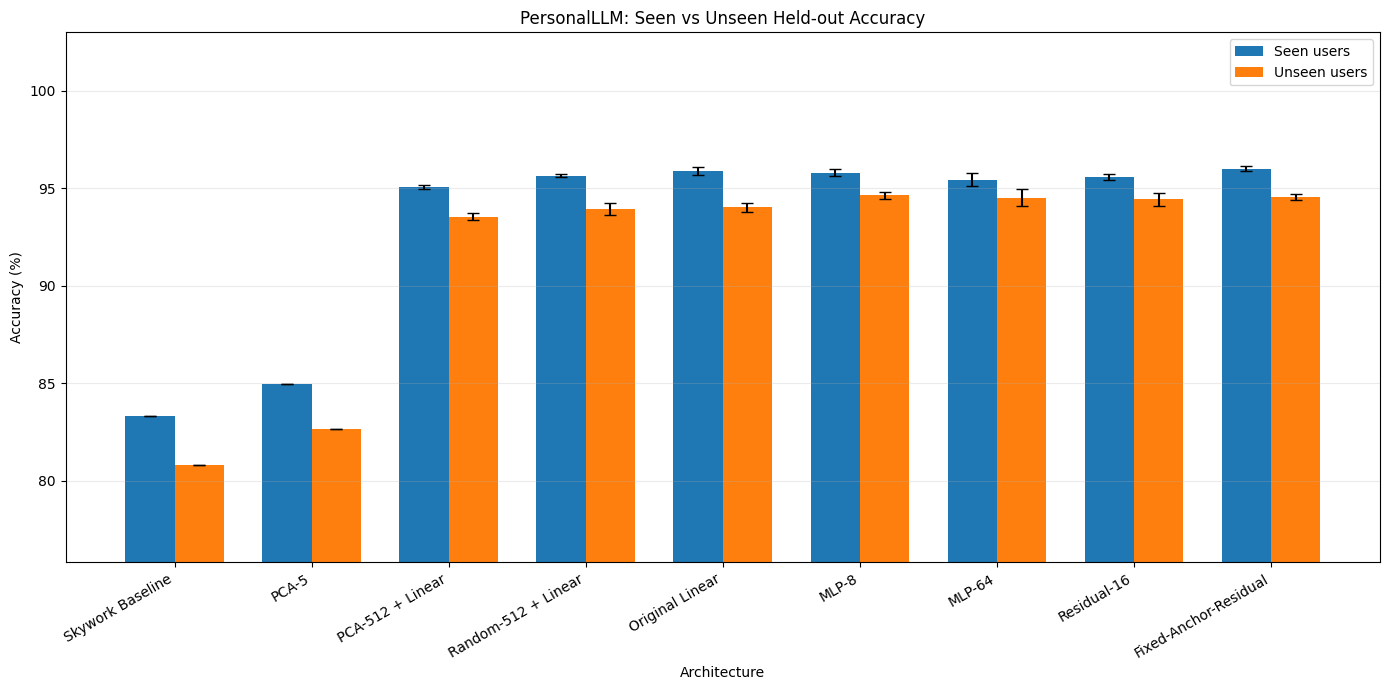

Saved: /content/drive/MyDrive/LoRe/Architecture_Ablations/final_v1/final_comparison/personalllm_heldout_accuracy.png


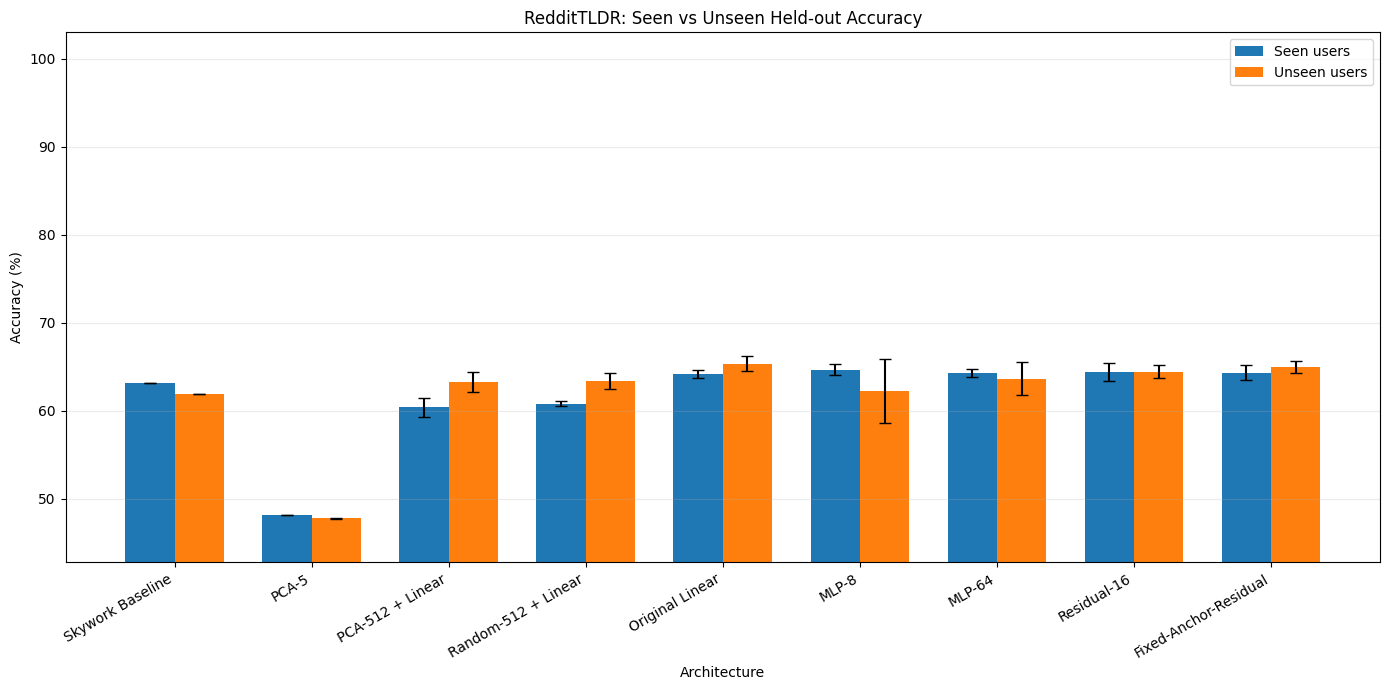

Saved: /content/drive/MyDrive/LoRe/Architecture_Ablations/final_v1/final_comparison/reddittldr_heldout_accuracy.png

Held-out accuracy visualizations complete.


In [ ]:

# ============================================================
# CELL 17: HELD-OUT ACCURACY COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

ARCHITECTURE_ORDER = [
    "Skywork Baseline",
    "PCA-5",
    "PCA-512 + Linear",
    "Random-512 + Linear",
    "Original Linear",
    "MLP-8",
    "MLP-64",
    "Residual-16",
    "Fixed-Anchor-Residual",
]

PLOT_DIR = OUTPUT_DIR / "final_comparison"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

for benchmark_name in BENCHMARK_NAMES:

    subset = (
        final_results_df[
            final_results_df["benchmark"] == benchmark_name
        ]
        .set_index("architecture")
        .reindex(ARCHITECTURE_ORDER)
        .dropna(subset=["unseen_eval_mean"])
    )

    architectures = subset.index.tolist()
    x = np.arange(len(architectures))
    width = 0.36

    seen_mean = subset["seen_eval_mean"].to_numpy() * 100
    unseen_mean = subset["unseen_eval_mean"].to_numpy() * 100

    seen_sd = (
        subset["seen_eval_seed_sd"]
        .fillna(0).to_numpy() * 100
    )

    unseen_sd = (
        subset["unseen_eval_seed_sd"]
        .fillna(0).to_numpy() * 100
    )

    fig, ax = plt.subplots(figsize=(14, 7))

    ax.bar(
        x - width / 2,
        seen_mean,
        width,
        yerr=seen_sd,
        capsize=4,
        label="Seen users"
    )

    ax.bar(
        x + width / 2,
        unseen_mean,
        width,
        yerr=unseen_sd,
        capsize=4,
        label="Unseen users"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        architectures,
        rotation=30,
        ha="right"
    )

    ax.set_ylabel("Accuracy (%)")
    ax.set_xlabel("Architecture")
    ax.set_title(
        f"{benchmark_name}: Seen vs Unseen Held-out Accuracy"
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    ax.set_ylim(
        max(0, min(seen_mean.min(), unseen_mean.min()) - 5),
        103
    )

    plt.tight_layout()

    filename = (
        PLOT_DIR /
        f"{benchmark_name.lower()}_heldout_accuracy.png"
    )

    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", filename)

print("\nHeld-out accuracy visualizations complete.")


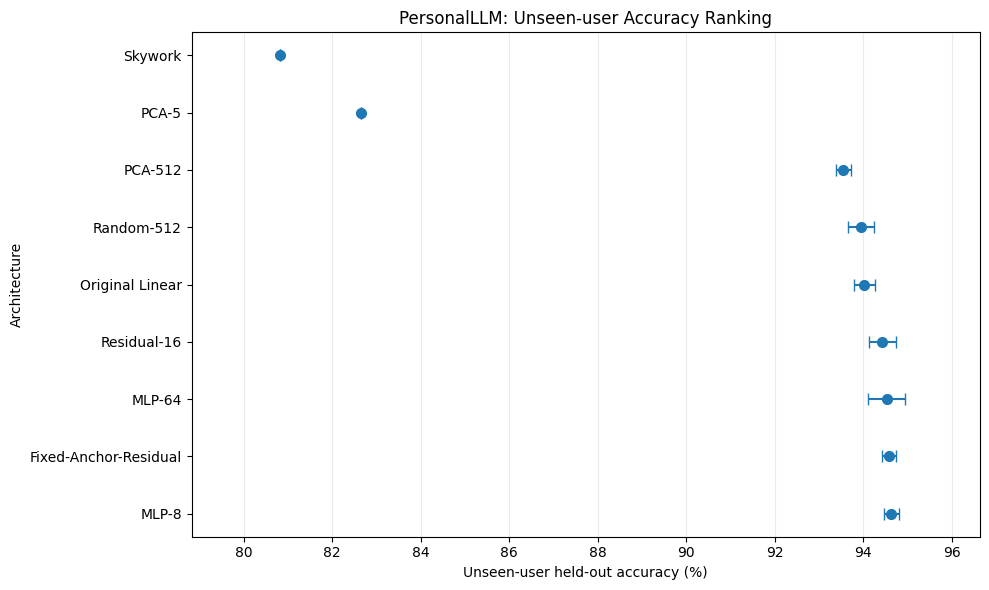

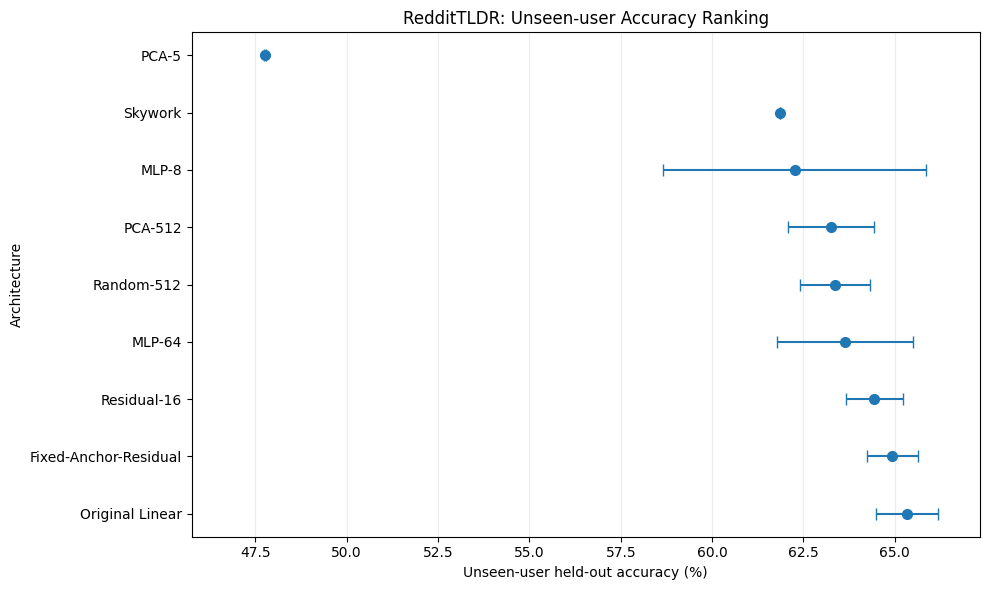

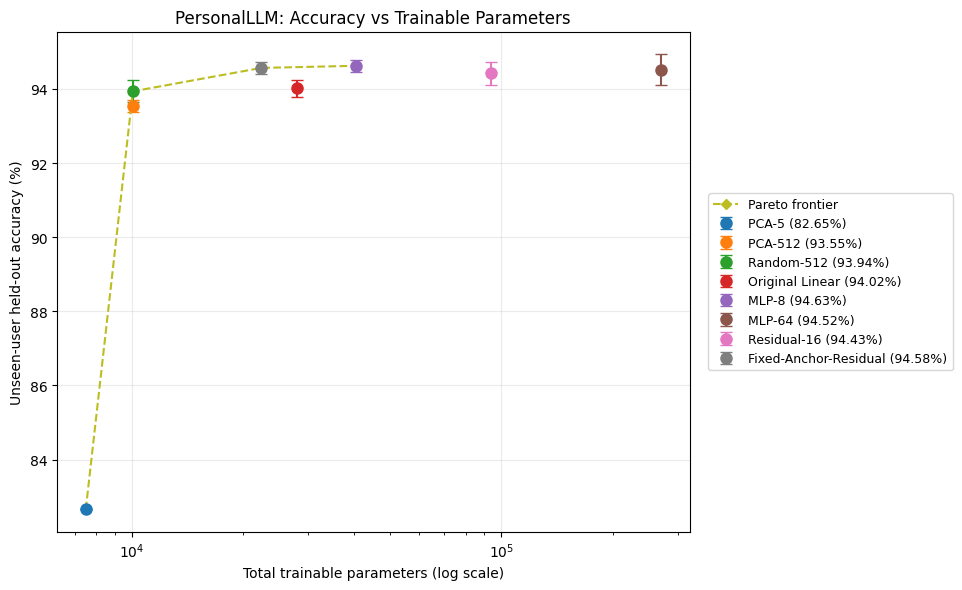

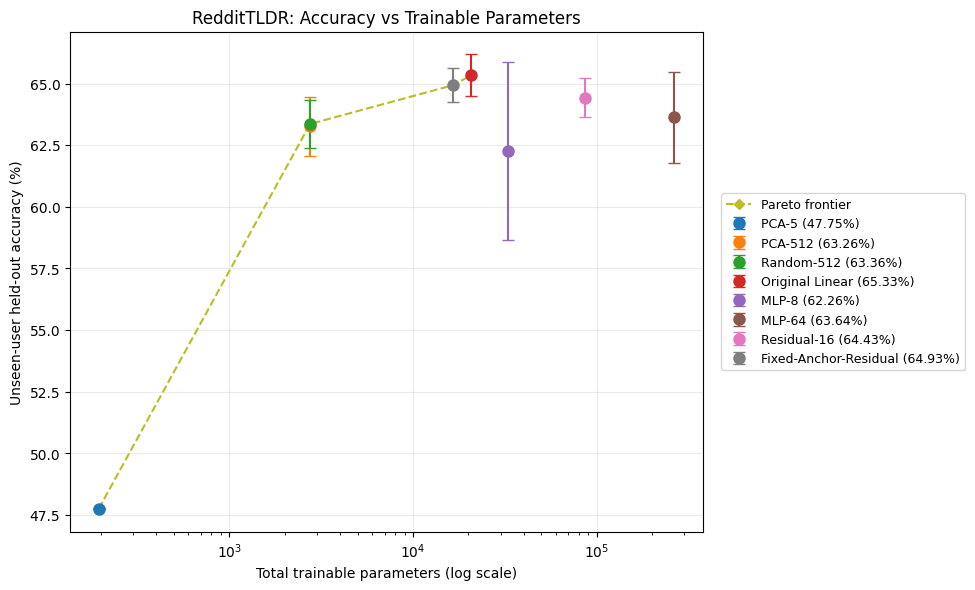

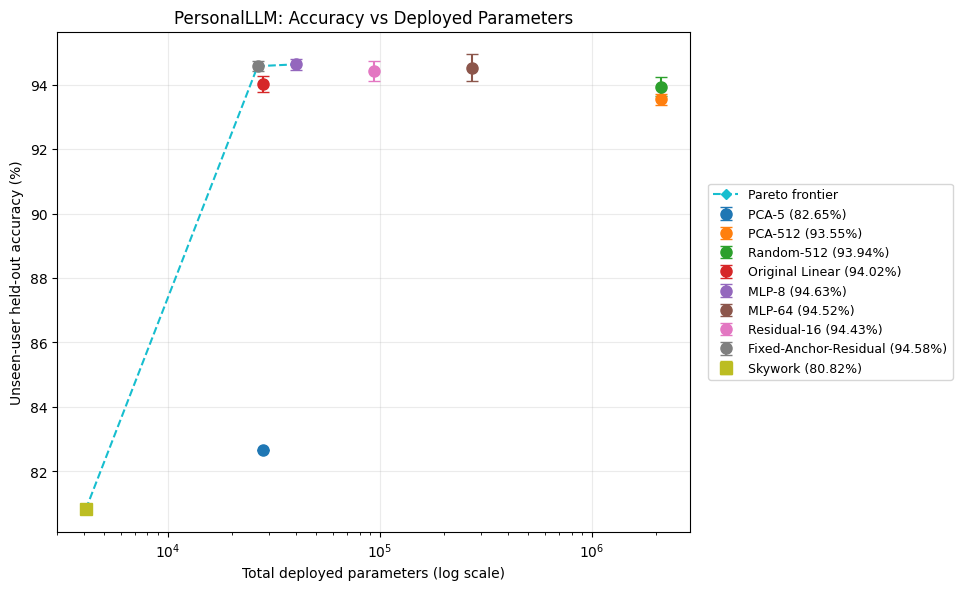

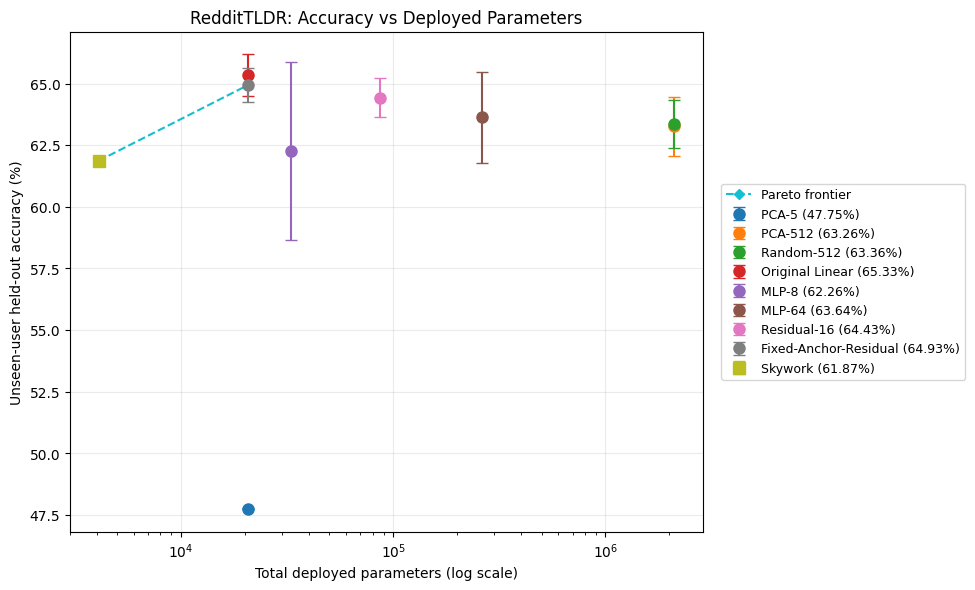

FINAL PARAMETER EFFICIENCY


,benchmark,architecture,unseen_accuracy_pct,unseen_seed_sd_pct,gain_vs_original_pp,total_trainable,total_deployed_params,pareto_trainable,pareto_deployed
4,PersonalLLM,MLP-8,94.63,0.17,0.61,40321,40321,True,True
7,PersonalLLM,Fixed-Anchor-Residual,94.58,0.15,0.56,22384,26480,True,True
5,PersonalLLM,MLP-64,94.52,0.42,0.50,270033,270033,False,False
6,PersonalLLM,Residual-16,94.43,0.31,0.41,93596,93596,False,False
3,PersonalLLM,Original Linear,94.02,0.24,0.00,27980,27980,False,False
2,PersonalLLM,Random-512 + Linear,93.94,0.30,-0.08,10060,2107212,True,False
1,PersonalLLM,PCA-512 + Linear,93.55,0.17,-0.48,10060,2107212,False,False
0,PersonalLLM,PCA-5,82.65,0.00,-11.37,7500,27980,True,False
8,PersonalLLM,Skywork Baseline,80.82,0.00,-13.20,0,4096,False,True
12,RedditTLDR,Original Linear,65.33,0.85,0.00,20675,20675,True,True


Saved parameter-efficiency tables.
Saved six clean figures to: /content/drive/MyDrive/LoRe/Architecture_Ablations/final_v1/final_comparison


In [ ]:

# ============================================================
# CELL 18: FINAL CLEAN VISUALIZATIONS & PARAMETER EFFICIENCY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PLOT_DIR = OUTPUT_DIR / "final_comparison"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

SHORT_NAMES = {
    "Skywork Baseline": "Skywork",
    "PCA-5": "PCA-5",
    "PCA-512 + Linear": "PCA-512",
    "Random-512 + Linear": "Random-512",
    "Original Linear": "Original Linear",
    "MLP-8": "MLP-8",
    "MLP-64": "MLP-64",
    "Residual-16": "Residual-16",
    "Fixed-Anchor-Residual": "Fixed-Anchor-Residual",
}

# ============================================================
# 1. PARETO FRONTIER FUNCTION
# ============================================================

def find_pareto_frontier(data, x_col, y_col):

    frontier = []

    for idx, candidate in data.iterrows():

        dominated = False

        for other_idx, other in data.iterrows():

            if idx == other_idx:
                continue

            better_or_equal_x = (
                other[x_col] <= candidate[x_col]
            )

            better_or_equal_y = (
                other[y_col] >= candidate[y_col]
            )

            strictly_better = (
                other[x_col] < candidate[x_col]
                or other[y_col] > candidate[y_col]
            )

            if (
                better_or_equal_x
                and better_or_equal_y
                and strictly_better
            ):
                dominated = True
                break

        if not dominated:
            frontier.append(candidate["architecture"])

    return frontier


# ============================================================
# 2. PREPARE DATA FOR BOTH BENCHMARKS
# ============================================================

efficiency_tables = {}

for benchmark_name in BENCHMARK_NAMES:

    data = final_results_df[
        final_results_df["benchmark"] == benchmark_name
    ].copy().reset_index(drop=True)

    data["unseen_accuracy_pct"] = (
        data["unseen_eval_mean"] * 100
    )

    data["seen_accuracy_pct"] = (
        data["seen_eval_mean"] * 100
    )

    data["unseen_seed_sd_pct"] = (
        data["unseen_eval_seed_sd"].fillna(0) * 100
    )

    data["seen_seed_sd_pct"] = (
        data["seen_eval_seed_sd"].fillna(0) * 100
    )

    # Improvement relative to Original Linear
    original_accuracy = data.loc[
        data["architecture"] == "Original Linear",
        "unseen_accuracy_pct"
    ].iloc[0]

    data["gain_vs_original_pp"] = (
        data["unseen_accuracy_pct"] - original_accuracy
    )

    # Pareto frontier: trainable parameters
    trainable_data = data[
        data["architecture"] != "Skywork Baseline"
    ]

    trainable_frontier = find_pareto_frontier(
        trainable_data,
        "total_trainable",
        "unseen_accuracy_pct"
    )

    # Pareto frontier: deployed parameters
    deployed_frontier = find_pareto_frontier(
        data,
        "total_deployed_params",
        "unseen_accuracy_pct"
    )

    data["pareto_trainable"] = (
        data["architecture"].isin(trainable_frontier)
    )

    data["pareto_deployed"] = (
        data["architecture"].isin(deployed_frontier)
    )

    efficiency_tables[benchmark_name] = data


# ============================================================
# 3. FIGURE A: ACCURACY RANKING
# ============================================================

for benchmark_name, data in efficiency_tables.items():

    ranked = data.sort_values(
        "unseen_accuracy_pct",
        ascending=True
    ).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(10, 6))

    y = np.arange(len(ranked))

    ax.errorbar(
        ranked["unseen_accuracy_pct"],
        y,
        xerr=ranked["unseen_seed_sd_pct"],
        fmt="o",
        capsize=4,
        markersize=7
    )

    ax.set_yticks(y)

    ax.set_yticklabels([
        SHORT_NAMES[name]
        for name in ranked["architecture"]
    ])

    ax.set_xlabel("Unseen-user held-out accuracy (%)")
    ax.set_ylabel("Architecture")

    ax.set_title(
        f"{benchmark_name}: Unseen-user Accuracy Ranking"
    )

    minimum = ranked["unseen_accuracy_pct"].min()
    maximum = ranked["unseen_accuracy_pct"].max()

    ax.set_xlim(
        max(0, minimum - 2),
        min(105, maximum + 2)
    )

    ax.grid(axis="x", alpha=0.25)
    ax.invert_yaxis()

    plt.tight_layout()

    filename = (
        PLOT_DIR /
        f"{benchmark_name.lower()}_accuracy_ranking.png"
    )

    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


# ============================================================
# 4. FIGURE B: ACCURACY VS TRAINABLE PARAMETERS
# ============================================================

for benchmark_name, data in efficiency_tables.items():

    plot_data = data[
        data["architecture"] != "Skywork Baseline"
    ].copy()

    frontier_data = plot_data[
        plot_data["pareto_trainable"]
    ].sort_values("total_trainable")

    fig, ax = plt.subplots(figsize=(11, 6.5))

    # Plot each architecture with a separate legend entry.
    for _, row in plot_data.iterrows():

        label = (
            f"{SHORT_NAMES[row['architecture']]} "
            f"({row['unseen_accuracy_pct']:.2f}%)"
        )

        ax.errorbar(
            row["total_trainable"],
            row["unseen_accuracy_pct"],
            yerr=row["unseen_seed_sd_pct"],
            fmt="o",
            markersize=8,
            capsize=4,
            label=label
        )

    # Pareto frontier
    ax.plot(
        frontier_data["total_trainable"],
        frontier_data["unseen_accuracy_pct"],
        linestyle="--",
        linewidth=1.5,
        marker="D",
        markersize=5,
        label="Pareto frontier"
    )

    ax.set_xscale("log")

    ax.set_xlabel("Total trainable parameters (log scale)")
    ax.set_ylabel("Unseen-user held-out accuracy (%)")

    ax.set_title(
        f"{benchmark_name}: Accuracy vs Trainable Parameters"
    )

    ax.grid(alpha=0.25)

    # Move the legend outside the plotting area.
    ax.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=9,
        frameon=True
    )

    fig.subplots_adjust(right=0.70)

    filename = (
        PLOT_DIR /
        f"{benchmark_name.lower()}_trainable_efficiency.png"
    )

    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


# ============================================================
# 5. FIGURE C: ACCURACY VS DEPLOYED PARAMETERS
# ============================================================

for benchmark_name, data in efficiency_tables.items():

    frontier_data = data[
        data["pareto_deployed"]
    ].sort_values("total_deployed_params")

    fig, ax = plt.subplots(figsize=(11, 6.5))

    for _, row in data.iterrows():

        label = (
            f"{SHORT_NAMES[row['architecture']]} "
            f"({row['unseen_accuracy_pct']:.2f}%)"
        )

        marker = (
            "s" if row["architecture"] == "Skywork Baseline"
            else "o"
        )

        ax.errorbar(
            row["total_deployed_params"],
            row["unseen_accuracy_pct"],
            yerr=row["unseen_seed_sd_pct"],
            fmt=marker,
            markersize=8,
            capsize=4,
            label=label
        )

    # Pareto frontier
    ax.plot(
        frontier_data["total_deployed_params"],
        frontier_data["unseen_accuracy_pct"],
        linestyle="--",
        linewidth=1.5,
        marker="D",
        markersize=5,
        label="Pareto frontier"
    )

    ax.set_xscale("log")

    ax.set_xlabel("Total deployed parameters (log scale)")
    ax.set_ylabel("Unseen-user held-out accuracy (%)")

    ax.set_title(
        f"{benchmark_name}: Accuracy vs Deployed Parameters"
    )

    ax.grid(alpha=0.25)

    ax.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=9,
        frameon=True
    )

    fig.subplots_adjust(right=0.70)

    filename = (
        PLOT_DIR /
        f"{benchmark_name.lower()}_deployed_efficiency.png"
    )

    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


# ============================================================
# 6. DISPLAY PARAMETER EFFICIENCY TABLES
# ============================================================

efficiency_df = pd.concat(
    efficiency_tables.values(),
    ignore_index=True
)

display_columns = [
    "benchmark",
    "architecture",
    "unseen_accuracy_pct",
    "unseen_seed_sd_pct",
    "gain_vs_original_pp",
    "total_trainable",
    "total_deployed_params",
    "pareto_trainable",
    "pareto_deployed"
]

print("=" * 90)
print("FINAL PARAMETER EFFICIENCY")
print("=" * 90)

display(
    efficiency_df[display_columns]
    .sort_values(
        ["benchmark", "unseen_accuracy_pct"],
        ascending=[True, False]
    )
    .round(2)
)

# ============================================================
# 7. SAVE FINAL TABLES
# ============================================================

efficiency_df.to_csv(
    OUTPUT_DIR / "summaries" / "parameter_efficiency.csv",
    index=False
)

efficiency_df.to_json(
    OUTPUT_DIR / "summaries" / "parameter_efficiency.json",
    orient="records",
    indent=2
)



print("Saved parameter-efficiency tables.")
print("Saved six clean figures to:", PLOT_DIR)
